In [1]:
import os
import xlwings as xw
import matplotlib.pyplot as plt
import pandas as pd

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Evening Peak Demand  3196 non-null   Float64
dtypes: Float64(1)
memory usage: 28.2 KB
None
       Evening Peak Demand
count          3196.000000
mean          10427.696854
std            2303.856578
min            4554.000000
25%            8609.250000
50%           10000.000000
75%           12106.250000
max           17200.000000
df1 :        Evening Peak Demand       Date
0                  5891.0 2016-01-01
1                  6538.0 2016-02-01
2                  6635.0 2016-03-01
3                  6694.0 2016-04-01
4                  6672.0 2016-05-01
...                   ...        ...
3191              12475.0        NaT
3192              12372.0        NaT
3193              14700.0        NaT
3194              15200.0        NaT
3195              15420.0        NaT

[31

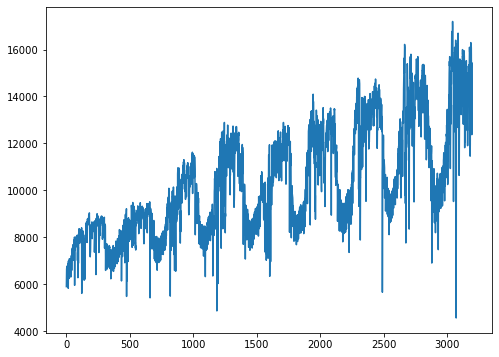

In [5]:
df=pd.read_csv('Monthly_data_preprocessed_ver_Final.csv')

df1=df.filter(['Evening Peak Demand', 'Date']).convert_dtypes()
df1['Date'] = pd.to_datetime(df1['Date'], errors='coerce',infer_datetime_format=True)
df2=df.filter(['Evening Peak Demand']).convert_dtypes()

print(df2.info())
print(df2.describe())
plt.figure(figsize=[8,6])

print("df1 : ", df1)
plt.plot(df2[['Evening Peak Demand']])

plt.show()

In [6]:
data=pd.read_csv('Monthly_data_preprocessed_ver_Final.csv')
df3=data.filter(['Evening Peak Demand']).convert_dtypes()

print(df3.info())
print(df3.describe())


n= df3['Evening Peak Demand'].count()
print(n)

dates = pd.date_range(start='2016-01-01', periods=n, freq='D')
df3['Dates']=dates

values = df2['Evening Peak Demand'].values


data1 = pd.DataFrame({'Date': dates, 'value': values})

df3.set_index('Dates', inplace=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Evening Peak Demand  3196 non-null   Float64
dtypes: Float64(1)
memory usage: 28.2 KB
None
       Evening Peak Demand
count          3196.000000
mean          10427.696854
std            2303.856578
min            4554.000000
25%            8609.250000
50%           10000.000000
75%           12106.250000
max           17200.000000
3196


In [7]:
print("data1 info \n\n",data1.info())
print("df1 info \n\n",df1.info())
print("df2 info \n\n",df2.info())
print("df3 info \n\n",df3.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    3196 non-null   datetime64[ns]
 1   value   3196 non-null   Float64       
dtypes: Float64(1), datetime64[ns](1)
memory usage: 53.2 KB
data1 info 

 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Evening Peak Demand  3196 non-null   Float64       
 1   Date                 1259 non-null   datetime64[ns]
dtypes: Float64(1), datetime64[ns](1)
memory usage: 53.2 KB
df1 info 

 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Evening Peak Dema

In [8]:
data1.head()

,Date,value
0,2016-01-01,5891.0
1,2016-01-02,6538.0
2,2016-01-03,6635.0
3,2016-01-04,6694.0
4,2016-01-05,6672.0


In [9]:
type(data1[['value']])

pandas.core.frame.DataFrame

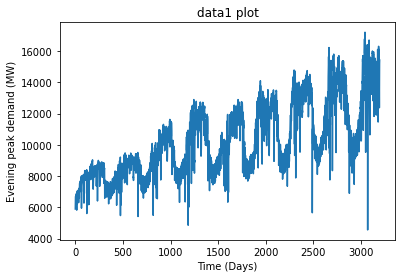

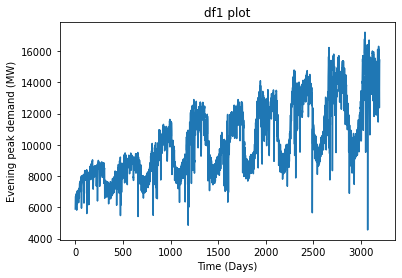

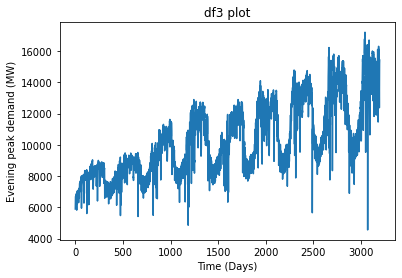

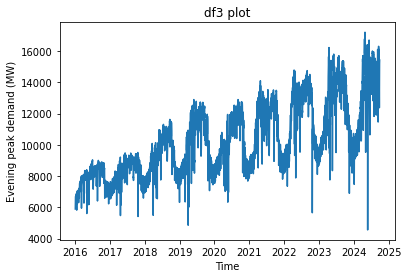

In [10]:
plt.plot(data1.index, data1[['value']])
plt.xlabel("Time (Days)")
plt.ylabel("Evening peak demand (MW)")
plt.title('data1 plot')
plt.show()
plt.plot(df1[['Evening Peak Demand']])
plt.xlabel("Time (Days)")
plt.ylabel("Evening peak demand (MW)")
plt.title('df1 plot')
plt.show()
plt.plot(df2[['Evening Peak Demand']])
plt.xlabel("Time (Days)")
plt.ylabel("Evening peak demand (MW)")
plt.title('df3 plot')
plt.show()

plt.plot(df3[['Evening Peak Demand']])
plt.xlabel("Time")
plt.ylabel("Evening peak demand (MW)")
plt.title('df3 plot')
plt.show()

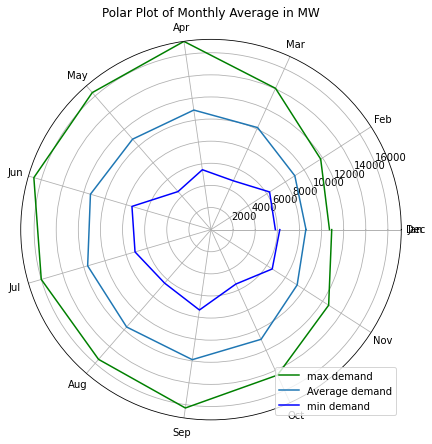

In [11]:
import numpy as np

data1['Month_Num'] = data1['Date'].dt.month

monthly_average = df3.groupby(df3.index.month)['Evening Peak Demand'].mean()

theta = np.linspace(0, 2 * np.pi, len(monthly_average))
radii = monthly_average.values
monthly_min = df3.groupby(df3.index.month)['Evening Peak Demand'].min()
monthly_max = df3.groupby(df3.index.month)['Evening Peak Demand'].max()
radii1=monthly_min.values
radii2=monthly_max.values

plt.figure(figsize=(9, 7))
plt.polar(theta, list(radii2),  color='green', label='max demand')
plt.polar(theta, list(radii),label='Average demand')
plt.polar(theta, list(radii1),  color='blue', label='min demand')

plt.title('Polar Plot of Monthly Average in MW')
plt.xticks(theta, ['Jan', 'Feb', 'Mar', 'Apr', 'May',
                   'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.ylim(0, radii2.max() + 10)
plt.legend(loc='lower right')
plt.show()

In [47]:
print(df3[['Evening Peak Demand']].groupby(df3.index.month).describe())

      Evening Peak Demand                                               \
                    count          mean          std     min       25%   
Dates                                                                    
1                   279.0   8595.921147  1156.837214  5821.0   7681.00   
2                   255.0   9012.254902  1239.908233  6300.0   8021.50   
3                   279.0  10146.383513  1840.528156  4855.0   8508.00   
4                   270.0  10925.829630  2794.562074  5473.0   8472.50   
5                   279.0  10827.850179  2557.977846  4554.0   8487.50   
6                   270.0  11364.355556  2255.802524  7452.0   9243.25   
7                   279.0  11628.817010  2280.944471  7162.0  10077.00   
8                   279.0  11654.648746  2065.133301  6406.0   9695.50   
9                   270.0  11884.796296  2252.203821  7345.0  10304.00   
10                  248.0  10907.145161  1877.323457  5413.0   9176.25   
11                  240.0   9262.77500

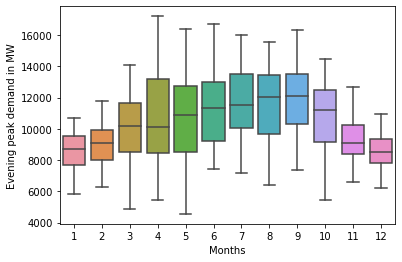

In [49]:
import seaborn as sns
sns.boxplot(x=df3.index.month, y=df3['Evening Peak Demand'], data=df3)
plt.xlabel("Months")
plt.ylabel("Evening peak demand in MW")
plt.show()
#sns.violinplot(data=df3, y=df3.index.month, x=df3['Evening Peak Demand'])
#plt.show()

In [50]:
file_path_new = "Monthly_data_Preprocessed_backup2.csv"
df_new = pd.read_csv(file_path_new)

df_new['Date'] = pd.to_datetime(df_new['Date'], format='%d/%m/%Y')
df_new.set_index('Date', inplace=True)

df_seaborn = df_new.copy()
df_seaborn['Month_Name'] = df_seaborn.index.month_name()
df_seaborn['Month_Name'] = pd.Categorical(df_seaborn['Month_Name'], categories=month_order, ordered=True)
df_seaborn['Year'] = df_seaborn.index.year

avg_monthly_demand = df_seaborn.groupby(['Year', 'Month_Name'])['Evening Peak Demand'].mean().reset_index()

g = sns.FacetGrid(avg_monthly_demand, col="Month_Name", col_wrap=4, height=3.5, aspect=1.3, sharey=True)
g.map_dataframe(sns.lineplot, x="Year", y="Evening Peak Demand", marker="o")
g.set_titles("{col_name}")
g.set_axis_labels("Year", "Evening Peak Demand (MW)")
g.fig.subplots_adjust(top=0.92)
g.fig.suptitle("Subseries Plot of Evening Peak Demand by Month (Seaborn Style)")
plt.show()


ValueError: time data '01-01-2016' does not match format '%d/%m/%Y' (match)

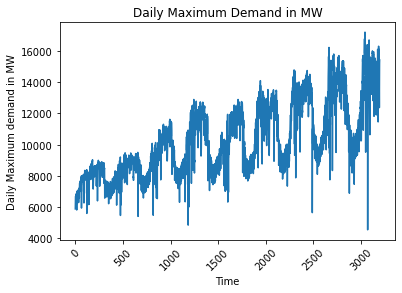

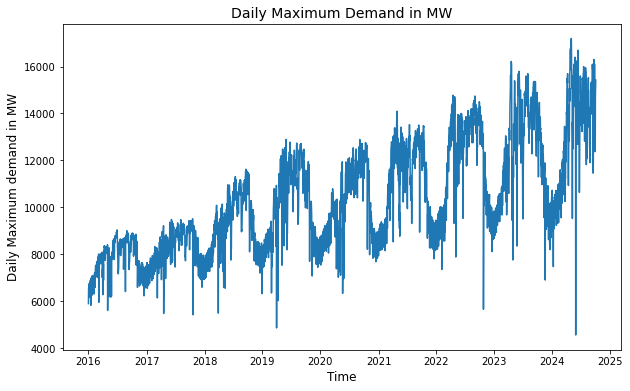

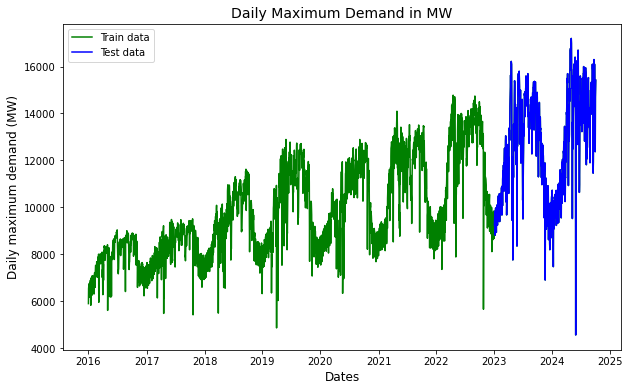

In [53]:

plt.plot(data1.index, data1[['value']])
plt.xlabel('Time')
plt.ylabel('Daily Maximum demand in MW')
plt.xticks(rotation = 45)
plt.title('Daily Maximum Demand in MW')
plt.show()

plt.figure(figsize=([10,6]))
plt.plot(df3.index, df3[['Evening Peak Demand']])
plt.xlabel('Time', fontsize=12)
plt.ylabel('Daily Maximum demand in MW', fontsize=12)
#plt.xticks(rotation = 45)
plt.title('Daily Maximum Demand in MW', fontsize=14)
plt.show()


N=len(df3)
training_test_ratio=0.8

trainData, testData = df3[0:int(N*training_test_ratio+1)], df3[int(N*training_test_ratio+1):]

plt.figure(figsize=([10,6]))
plt.plot(df3[['Evening Peak Demand']], 'green', label='Train data')
plt.plot(testData, 'blue', label='Test data')
plt.grid(False)
plt.xlabel('Dates' , fontsize=12)
plt.ylabel('Daily maximum demand (MW)', fontsize=12)
plt.title('Daily Maximum Demand in MW', fontsize=14)
plt.legend()


Text(0.5, 1.0, 'Histogram of Daily Maximum Electricity Demand')

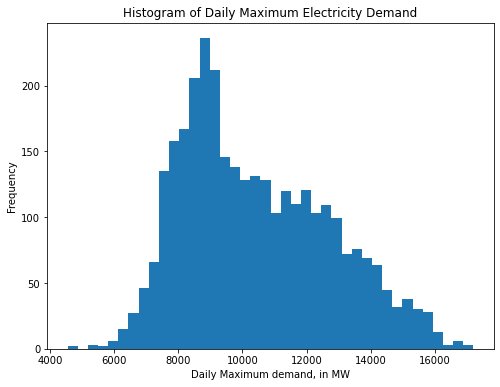

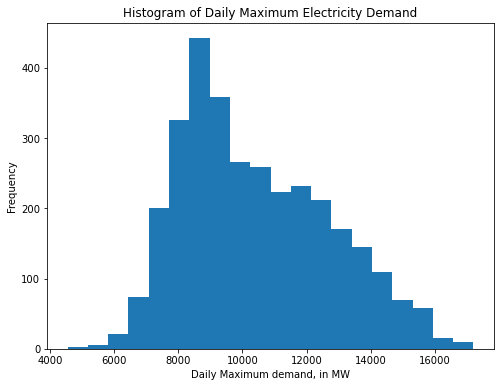

In [56]:


plt.figure(figsize=[8,6])
plt.hist(df2['Evening Peak Demand'], bins=40)
plt.ylabel('Frequency')
plt.xlabel('Daily Maximum demand, in MW')
plt.title('Histogram of Daily Maximum Electricity Demand')

plt.figure(figsize=[8,6])
plt.hist(df2['Evening Peak Demand'], bins=20)
plt.ylabel('Frequency')
plt.xlabel('Daily Maximum demand, in MW')
plt.title('Histogram of Daily Maximum Electricity Demand')

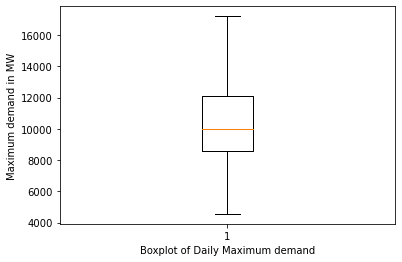

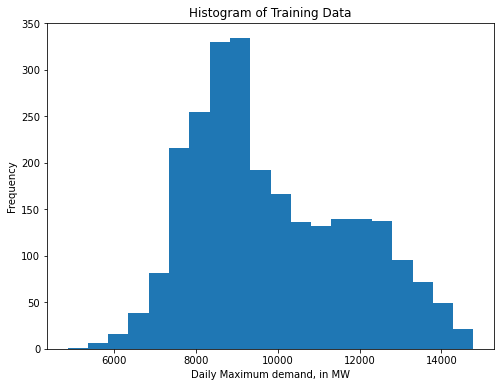

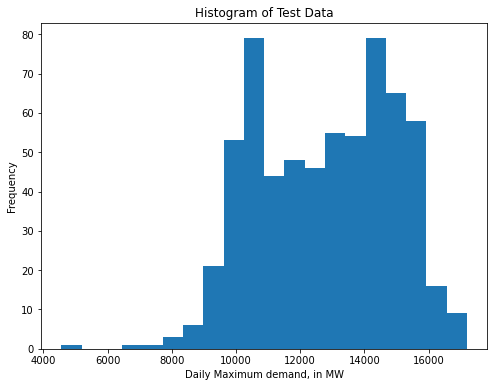

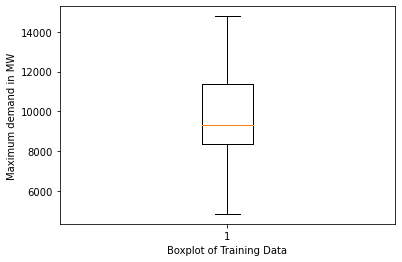

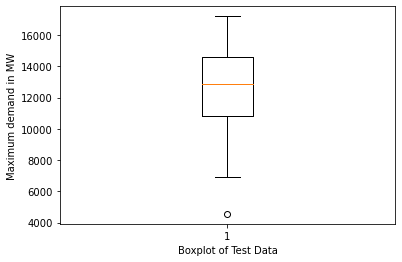

In [57]:
plt.boxplot(df2['Evening Peak Demand'])
plt.xlabel('Boxplot of Daily Maximum demand')
plt.ylabel('Maximum demand in MW')
plt.show()

plt.figure(figsize=[8,6])
plt.hist(trainData['Evening Peak Demand'], bins=20)
plt.ylabel('Frequency')
plt.xlabel('Daily Maximum demand, in MW')
plt.title('Histogram of Training Data')
plt.show()

plt.figure(figsize=[8,6])
plt.hist(testData['Evening Peak Demand'], bins=20)
plt.ylabel('Frequency')
plt.xlabel('Daily Maximum demand, in MW')
plt.title('Histogram of Test Data')
plt.show()

plt.boxplot(trainData)
plt.xlabel('Boxplot of Training Data')
plt.ylabel('Maximum demand in MW')
plt.show()

plt.boxplot(testData)
plt.xlabel('Boxplot of Test Data')
plt.ylabel('Maximum demand in MW')
plt.show()

In [58]:
## Statistical parameters and hypothesis testing

from statsmodels.tsa.stattools import adfuller, kpss
from scipy.stats import norm, kurtosis, skew, shapiro, normaltest

## Total Dataset

print("######################Total Dataset ##################################")
print(df2.describe())
print(df2.info())


print('mean =',df2.mean())

print('min =',df2.min())
print('max =',df2.max())
print('std =',df2.std())
print('skew =',df2.skew())
print('kurt =',df2.kurt())


print('\n\n Adf test :Ho: Non-Stationary, H1: Stationary \n',adfuller(df2['Evening Peak Demand']))
#H0: Non-Stationary
#H1: stationary
print('\n\n KPSS test : Ho: Stationary, H1: Not Stationary   \n',kpss(df2['Evening Peak Demand']))
#H0: Stationary
#H1: Non-stationary

# The Shapiro-Wilk test 
print('\n\n Shapiro Test: Ho: Data frm Normal Dist \n', shapiro(df2['Evening Peak Demand']))


#H0: data from normal distribution
#H1: data not from normal distribution    
print('\n\n skewness: ',skew(list(df2['Evening Peak Demand'].values)))
print('\n\n kurtosis: ',kurtosis(list(df2['Evening Peak Demand'].values)))


## Trainaing and Test Dataset
print("\n\n ###################### Training Dataset ##################################")

print(trainData.describe())
print(trainData.info())


print('mean =',trainData.mean())

print('min =',trainData.min())
print('max =',trainData.max())
print('std =',trainData.std())
print('skew =',trainData.skew())
print('kurt =',trainData.kurt())


print('\n\n Adf test :Ho: Non-Stationary, H1: Stationary \n',adfuller(trainData['Evening Peak Demand']))
#H0: Non-Stationary
#H1: stationary
print('\n\n KPSS test : Ho: Stationary, H1: Not Stationary   \n',kpss(trainData['Evening Peak Demand']))
#H0: Stationary
#H1: Non-stationary


# The Shapiro-Wilk test tests the null hypothesis that the data was drawn from a normal distribution.
print('\n\n Shapiro Test: Ho: Data frm Normal Dist \n', shapiro(trainData['Evening Peak Demand']))
#print(normaltest(dataset))

#H0: data from normal distribution
#H1: data not from normal distribution    
print('\n\n skewness: ',skew(list(trainData['Evening Peak Demand'].values)))
print('\n\n kurtosis: ',kurtosis(list(trainData['Evening Peak Demand'].values)))


print("\n\n ###################### Test Dataset ##################################")

print(testData.describe())
print(testData.info())


print('mean =',testData.mean())

print('min =',testData.min())
print('max =',testData.max())
print('std =',testData.std())
print('skew =',testData.skew())
print('kurt =',testData.kurt())


print('\n\n Adf test :Ho: Non-Stationary, H1: Stationary \n',adfuller(testData['Evening Peak Demand']))
#H0: Non-Stationary
#H1: stationary
print('\n\n KPSS test : Ho: Stationary, H1: Not Stationary   \n',kpss(testData['Evening Peak Demand']))
#H0: Stationary
#H1: Non-stationary

# The Shapiro-Wilk test tests the null hypothesis that the data was drawn from a normal distribution.
print('\n\n Shapiro Test: Ho: Data frm Normal Dist \n', shapiro(testData['Evening Peak Demand']))
#print(normaltest(dataset))

#H0: data from normal distribution
#H1: data not from normal distribution    
print('\n\n skewness: ',skew(list(testData['Evening Peak Demand'].values)))
print('\n\n kurtosis: ',kurtosis(list(testData['Evening Peak Demand'].values)))


######################Total Dataset ##################################
       Evening Peak Demand
count          3196.000000
mean          10427.696854
std            2303.856578
min            4554.000000
25%            8609.250000
50%           10000.000000
75%           12106.250000
max           17200.000000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196 entries, 0 to 3195
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Evening Peak Demand  3196 non-null   Float64
dtypes: Float64(1)
memory usage: 28.2 KB
None
mean = Evening Peak Demand    10427.696854
dtype: float64
min = Evening Peak Demand    4554.0
dtype: float64
max = Evening Peak Demand    17200.0
dtype: float64
std = Evening Peak Demand    2303.856578
dtype: float64
skew = Evening Peak Demand    0.482952
dtype: float64
kurt = Evening Peak Demand   -0.576329
dtype: float64


 Adf test :Ho: Non-Stationary, H1: Stationary 
 (-2.35639

<ipython-input-58-799c59e40f4b>:25: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  print('\n\n KPSS test : Ho: Stationary, H1: Not Stationary   \n',kpss(df2['Evening Peak Demand']))
<ipython-input-58-799c59e40f4b>:58: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  print('\n\n KPSS test : Ho: Stationary, H1: Not Stationary   \n',kpss(trainData['Evening Peak Demand']))


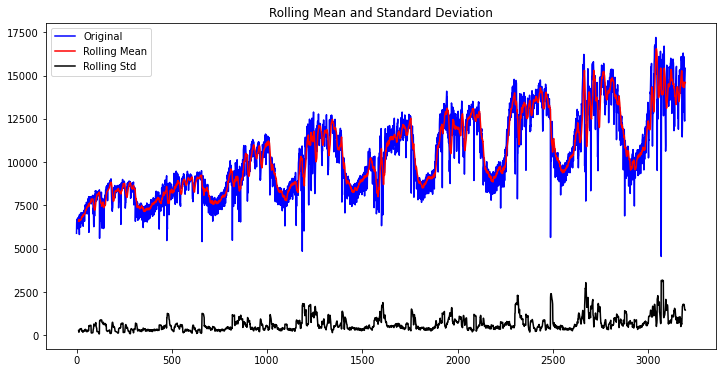

Results of dickey fuller test
Test Statistics                  -2.356391
p-value                           0.154425
No. of lags used                 28.000000
Number of observations used    3167.000000
critical value (1%)              -3.432417
critical value (5%)              -2.862453
critical value (10%)             -2.567256
dtype: float64


In [59]:
from statsmodels.tsa.stattools import adfuller

def test_stationarity(timeseries):
    #Determing rolling statistics
    rolmean = timeseries.rolling(12).mean()
    rolstd = timeseries.rolling(12).std()
    
    plt.figure(figsize=(12,6))
    plt.plot(timeseries, color='blue',label='Original')
    plt.plot(rolmean, color='red', label='Rolling Mean')
    plt.plot(rolstd, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean and Standard Deviation')
    plt.show(block=False)
    print("Results of dickey fuller test")
    adft = adfuller(timeseries,autolag='AIC')
    
    output = pd.Series(adft[0:4],index=['Test Statistics','p-value','No. of lags used','Number of observations used'])
    for key,values in adft[4].items():
        output['critical value (%s)'%key] =  values
    print(output)

test_stationarity(df2[['Evening Peak Demand']])

############# Multiplicative seasonality##############
0        7629.242930
1        7630.416348
2        7631.589765
3        7632.763183
4        7633.936601
            ...     
2551    12430.868898
2552    12433.393276
2553    12435.917654
2554    12438.442032
2555    12440.966409
Name: trend, Length: 2556, dtype: float64
############# Additive seasonality##############
0        7629.242930
1        7630.416348
2        7631.589765
3        7632.763183
4        7633.936601
            ...     
2551    12430.868898
2552    12433.393276
2553    12435.917654
2554    12438.442032
2555    12440.966409
Name: trend, Length: 2556, dtype: float64
############# STL seasonality##############
0        7533.848567
1        7535.473839
2        7537.098160
3        7538.721524
4        7540.343928
            ...     
2551    12395.013429
2552    12397.420061
2553    12399.825907
2554    12402.230966
2555    12404.635242
Name: trend, Length: 2556, dtype: float64


<Figure size 432x288 with 0 Axes>

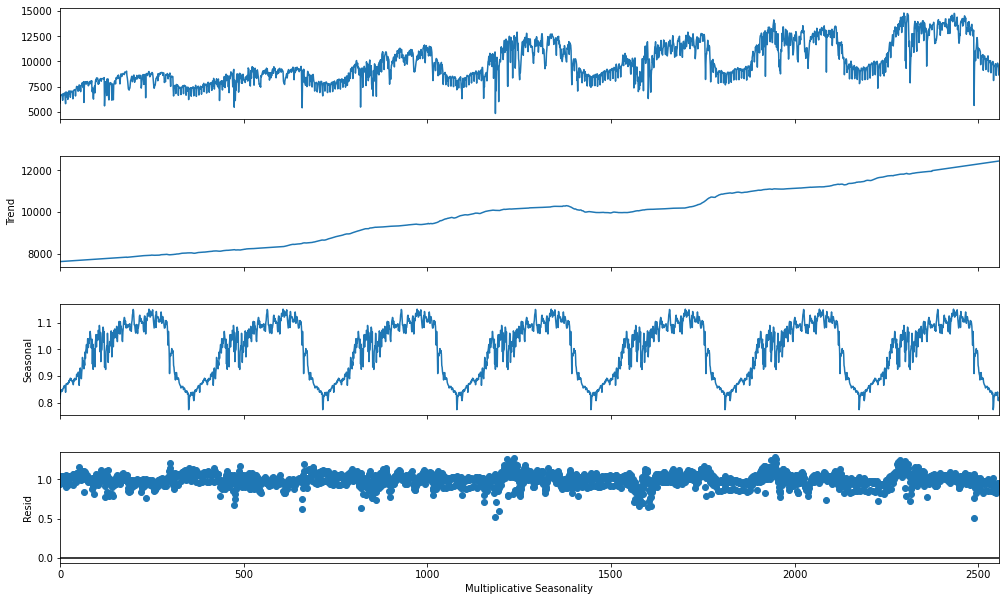

<Figure size 432x288 with 0 Axes>

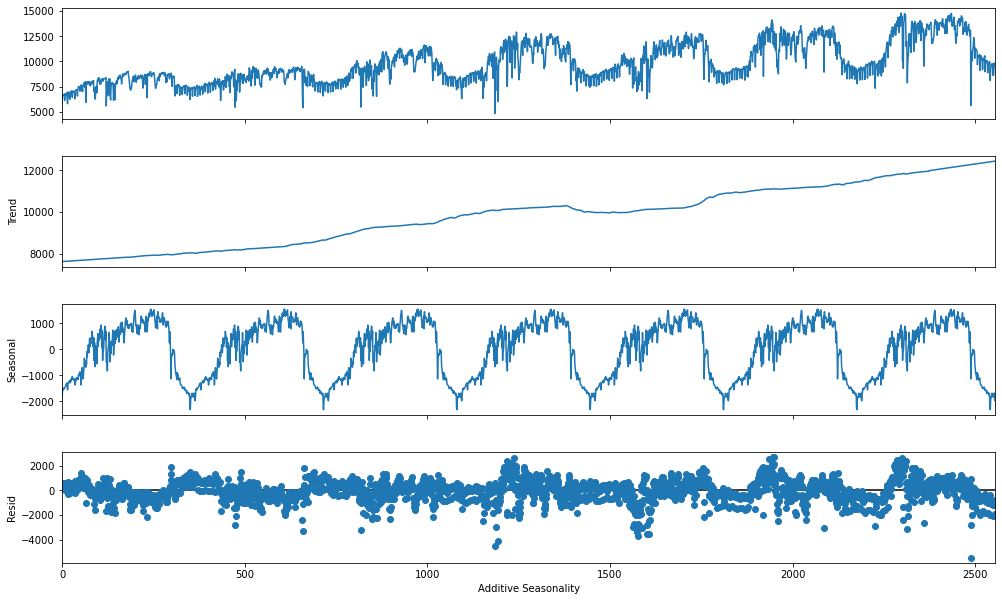

<Figure size 432x288 with 0 Axes>

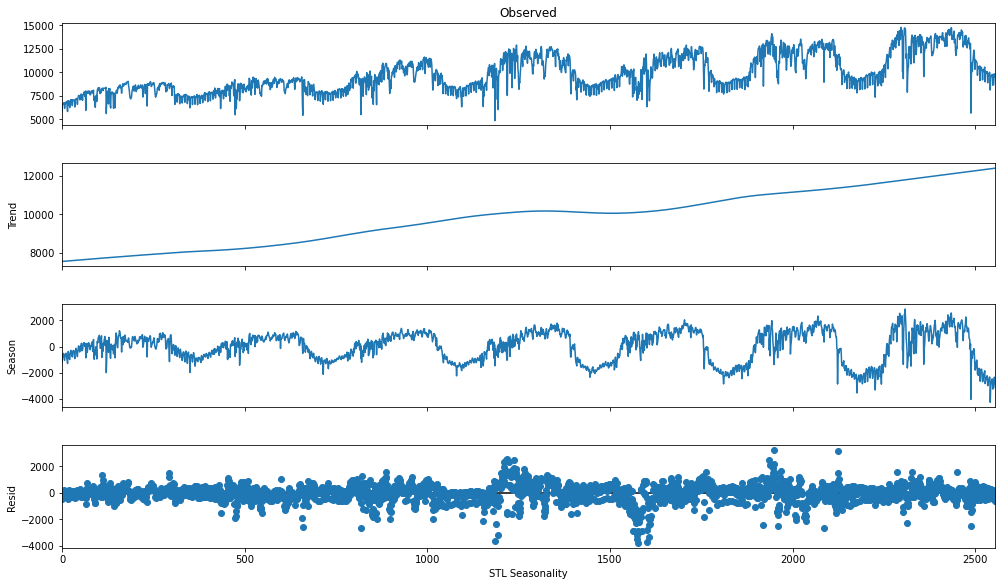

0        5891.0
1        6538.0
2        6635.0
3        6694.0
4        6672.0
         ...   
3191    12475.0
3192    12372.0
3193    14700.0
3194    15200.0
3195    15420.0
Name: Evening Peak Demand, Length: 3196, dtype: Float64


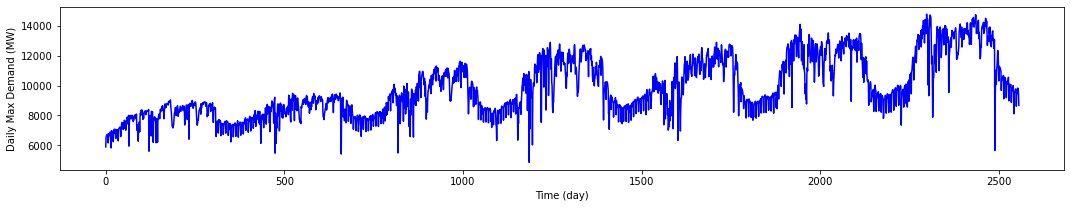

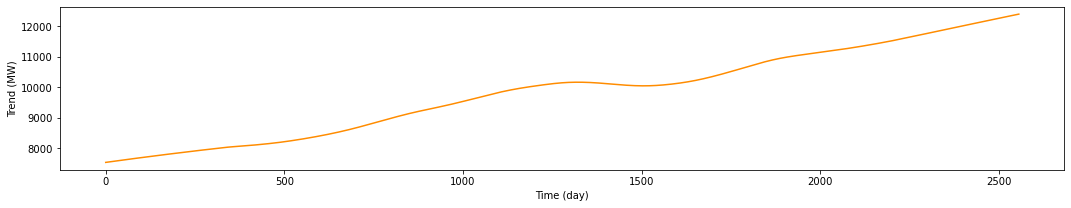

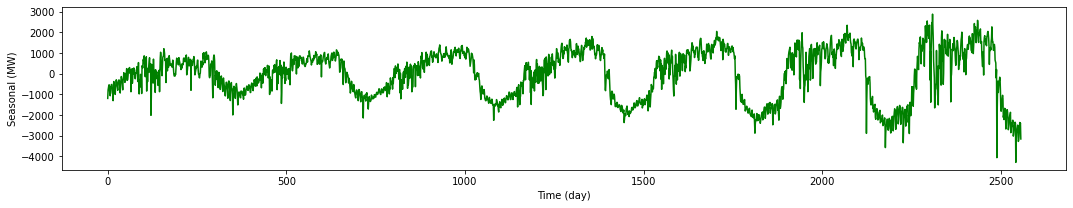

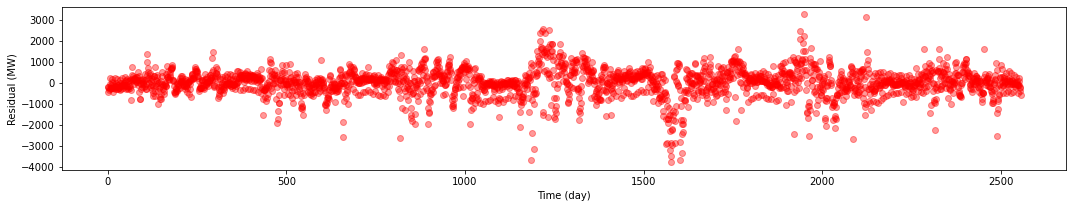

In [60]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

train_data, test_data = df2[0:int(len(df2)*0.8)], df2[int(len(df2)*0.8):]

print("############# Multiplicative seasonality##############")
result = seasonal_decompose(train_data, model='multiplicative', extrapolate_trend='freq', period=365)

print(result.trend)
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)
fig=plt.xlabel("Multiplicative Seasonality")

print("############# Additive seasonality##############")
result = seasonal_decompose(train_data, model='additive', extrapolate_trend='freq', period=365)

print(result.trend)
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)
fig=plt.xlabel("Additive Seasonality")

print("############# STL seasonality##############")

result = STL(train_data, period=365).fit()


print(result.trend)
fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)
fig = plt.xlabel("STL Seasonality")
plt.show()

print(df2['Evening Peak Demand'])

plt.figure(figsize=[18,3])
plt.plot(train_data, color='blue')
plt.xlabel("Time (day)")
plt.ylabel("Daily Max Demand (MW)")
plt.show()
plt.figure(figsize=[18,3])
plt.plot(result.trend, color='darkorange')
plt.xlabel("Time (day)")
plt.ylabel("Trend (MW)")
plt.show()
plt.figure(figsize=[18,3])
plt.plot(result.seasonal, color='green')
plt.xlabel("Time (day)")
plt.ylabel("Seasonal (MW)")
plt.show()
plt.figure(figsize=[18,3])
plt.scatter(train_data.index, result.resid, alpha=0.4, color='red')
plt.xlabel("Time (day)")
plt.ylabel("Residual (MW)")
plt.show()
#fig.show()

############# STL + ARIMA (15,1,12) ##############


C:\Users\dipu_\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\dipu_\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\dipu_\anaconda3\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


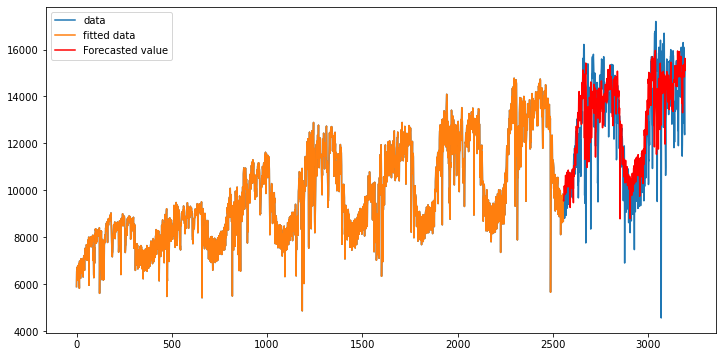

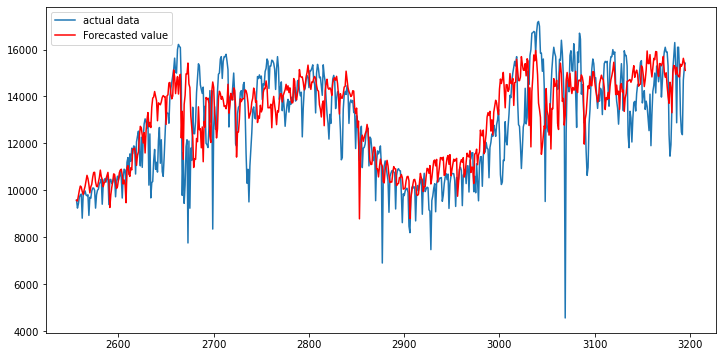

################  Result on test data ###################
Root Mean Squared Error (RMSE): 1517.611179110755
Mean Squared Error (MSE): 2303143.690961936
Mean Absolute Error (MAE): 1104.6700356335677
R2 Score: 0.49557058278853805
Explained Variance Score: 0.5134905846879299
Mean Absolute Percentage Error (MAPE): 9.22732975253826
Mean Percentage Error (MPE): -3.6178350110215556
                    STL Decomposition and SARIMAX Results                     
Dep. Variable:                      y   No. Observations:                 2556
Model:               ARIMA(15, 1, 12)   Log Likelihood              -19315.563
Date:                Thu, 07 Aug 2025   AIC                          38689.127
Time:                        14:48:17   BIC                          38858.655
Sample:                             0   HQIC                         38750.606
                               - 2556                                         
Covariance Type:                  opg                                

In [61]:
# STL + ARIMA 

print("############# STL + ARIMA (15,1,12) ##############")

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.forecasting.stl import STLForecast
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
import numpy as np


stlf = STLForecast(train_data, ARIMA, model_kwargs=dict(order=(15, 1, 12), trend="t"), period=365)
stlf_res = stlf.fit()

forecast = stlf_res.forecast(640)
forecast_STL_ARIMA=forecast


plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']], label='data')
plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast, color='red',label='Forecasted value')
plt.legend()
plt.show()

plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],test_data, label='actual data')
#plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast,color='red', label='Forecasted value')
plt.legend()
plt.show()


print("################  Result on test data ###################")


mse = mean_squared_error(test_data, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data, forecast)
r2 = r2_score(test_data, forecast)
evs = explained_variance_score(test_data, forecast)
mape = np.mean(np.abs((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values)) * 100
mpe = np.mean((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values) * 100

print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")

print(stlf_res.summary())

############# STL + Exponential Smoothing ##############


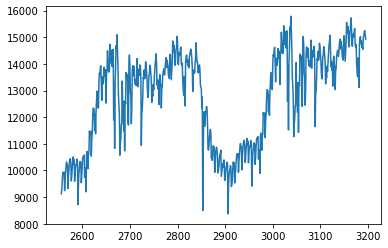

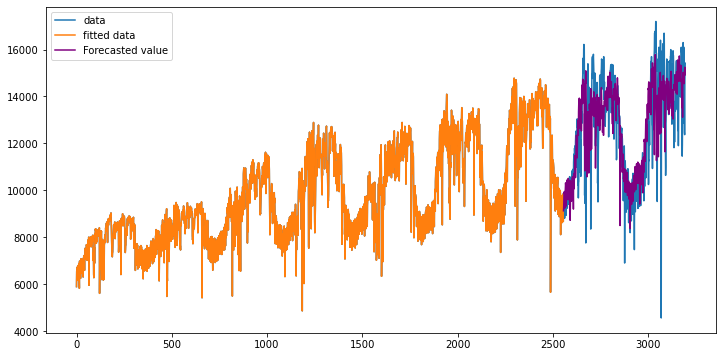

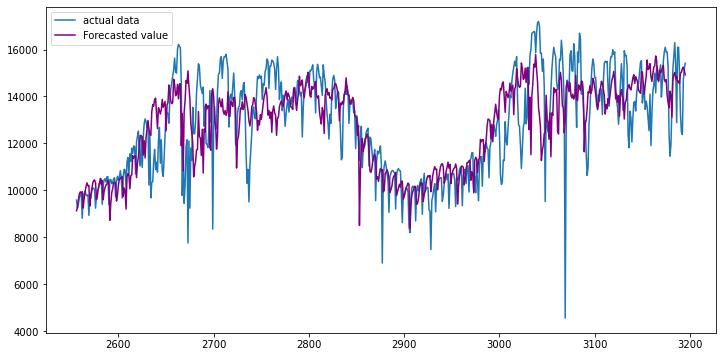

Root Mean Squared Error (RMSE): 1505.9473310306016
Mean Squared Error (MSE): 2267877.363838192
Mean Absolute Error (MAE): 1109.7259443330113
R2 Score: 0.5032945354485603
Explained Variance Score: 0.5033185822737831
Mean Absolute Percentage Error (MAPE): 9.105392582421821
Mean Percentage Error (MPE): -1.2400376995194287
             STL Decomposition and Exponential Smoothing Results              
Dep. Variable:                      y   No. Observations:                 2556
Model:                   ETS(A, A, N)   Log Likelihood              -19697.293
Date:                Thu, 07 Aug 2025   AIC                          39404.585
Time:                        16:15:35   BIC                          39433.816
Sample:                             0   HQIC                         39415.186
                               - 2556   Scale                       289154.087
Covariance Type:                  opg                                         
                      coef    std err          

In [106]:
# STL + Exponential Smoothing

print("############# STL + Exponential Smoothing ##############")

from statsmodels.tsa.statespace import exponential_smoothing
from statsmodels.tsa.forecasting.stl import STLForecast
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
import numpy as np

ES = exponential_smoothing.ExponentialSmoothing
config = {"trend": True}
stlf = STLForecast(train_data, ES, model_kwargs=config, period=365)
res = stlf.fit()
forecast_STL_ES = res.forecast(640)

plt.plot(forecast_STL_ES)


plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']], label='data')
plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast_STL_ES, color='purple', label='Forecasted value')
plt.legend()
plt.show()

plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],test_data, label='actual data')
#plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast_STL_ES,color='purple', label='Forecasted value')
plt.legend()
plt.show()


forecast=forecast_STL_ES



mse = mean_squared_error(test_data, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data, forecast)
r2 = r2_score(test_data, forecast)
evs = explained_variance_score(test_data, forecast)
mape = np.mean(np.abs((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values)) * 100
mpe = np.mean((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values) * 100

print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")


print(res.summary())

In [63]:
print(forecast)

2556     9124.398564
2557     9280.733601
2558     9609.019145
2559     9841.760134
2560     9934.024780
            ...     
3191    15033.716919
3192    15195.187442
3193    15248.408196
3194    15115.894368
3195    14922.181575
Length: 640, dtype: float64


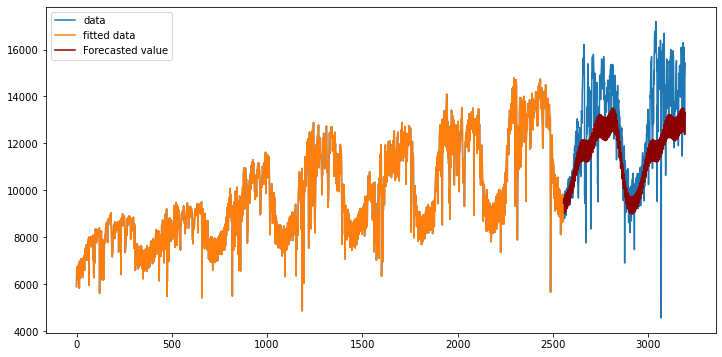

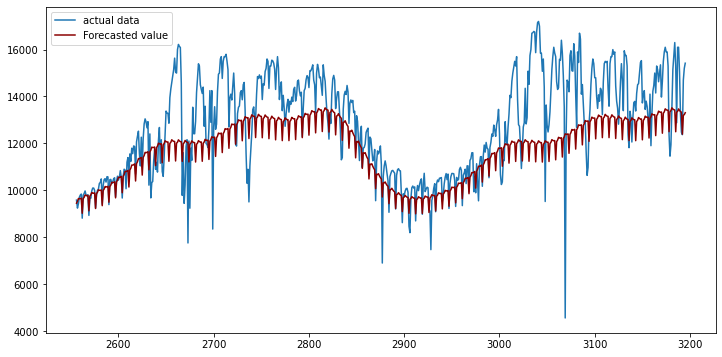

In [71]:
#TBEATS model


from tbats import TBATS



TBATS_model = TBATS(use_box_cox=True, 
                    use_trend=True, 
                    use_damped_trend=True,
                    use_arma_errors=True, 
                    seasonal_periods=[7, 365.25])  # weekly and yearly
fitted_TBATS_model = TBATS_model.fit(train_data)
forecast_TBATS = fitted_TBATS_model.forecast(steps=640)

#predictSTL=stlf_res.predict(len(train_data))

plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']], label='data')
plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast_TBATS,color='darkred', label='Forecasted value')
plt.legend()
plt.show()


plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],test_data, label='actual data')
#plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):], forecast_TBATS, color='darkred', label='Forecasted value')
plt.legend()
plt.show()


In [42]:
print(fitted_TBATS_model.summary())

# Time series analysis
print(fitted_TBATS_model.y_hat) # in sample prediction
print(fitted_TBATS_model.resid) # in sample residuals
print(fitted_TBATS_model.aic)
# Reading model parameters
print(fitted_TBATS_model.params.alpha)
print(fitted_TBATS_model.params.beta)
print(fitted_TBATS_model.params.x0)
print(fitted_TBATS_model.params.components.use_box_cox)
print(fitted_TBATS_model.params.components.seasonal_harmonics)

Use Box-Cox: False
Use trend: True
Use damped trend: True
Seasonal periods: [  7. 365.]
Seasonal harmonics [3 4]
ARMA errors (p, q): (0, 0)
Smoothing (Alpha): 0.673759
Trend (Beta): -0.140312
Damping Parameter (Phi): 0.800000
Seasonal Parameters (Gamma): [-9.16858204e-07  1.74026757e-08  1.91932547e-07  7.84635364e-08]
AR coefficients []
MA coefficients []
Seed vector [ 8.39014592e+03 -2.57049517e+00 -2.21010496e+02 -1.69854803e+02
 -1.83964319e+02 -1.46731007e+01 -2.07603887e+01  8.37310915e+00
 -1.39062566e+03 -5.61330342e+02 -8.22545695e+01  1.96782192e+02
 -3.90325951e+02  1.73203051e+02  1.10914449e+02  4.06179233e+00]

AIC 52808.810770


In [100]:
# STL + ETS

print("############# STL + ETS ##############")

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.exponential_smoothing.ets import ETSModel #, SARIMAX




stlf = STLForecast(train_data, ETSModel, period=365)
stlf_res = stlf.fit()

forecast_STL_ETS = stlf_res.forecast(640)


plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']], label='data')
plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast_STL_ETS,color='darkred', label='Forecasted value')
plt.legend()
plt.show()


plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],test_data, label='actual data')
#plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):], forecast_STL_ETS, color='darkred', label='Forecasted value')
plt.legend()
plt.show()






print("################  Result on test data ###################")

forecast=forecast_STL_ETS

mse = mean_squared_error(test_data, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data, forecast)
r2 = r2_score(test_data, forecast)
evs = explained_variance_score(test_data, forecast)
mape = np.mean(np.abs((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values)) * 100
mpe = np.mean((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")

print(stlf_res.summary())

############# STL + ETS ##############


TypeError: __init__() missing 1 required positional argument: 'endog'

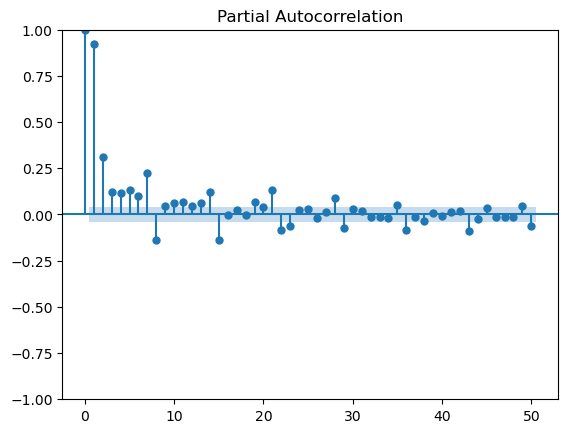

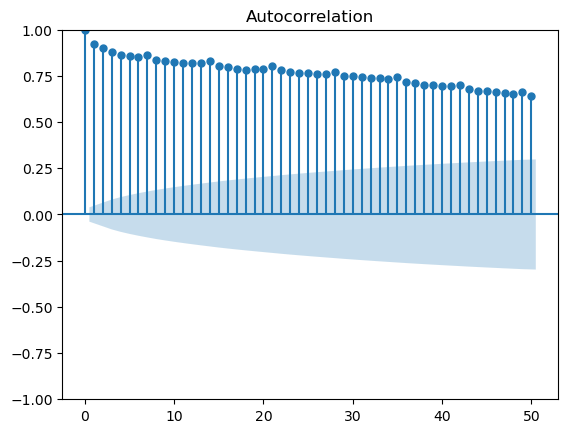

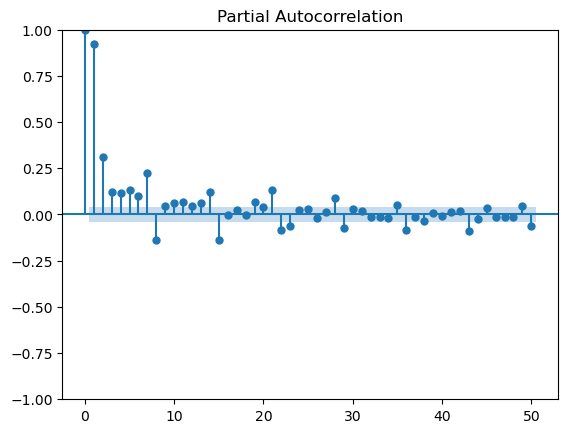

In [35]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf


plot_acf(trainData, lags=50)
plot_pacf(trainData, lags=50, method='ols')




 Adf test :Ho: Non-Stationary, H1: Stationary 
 (-13.805498516276598, 8.417162235725739e-26, 27, 3167, {'1%': -3.4324165008537446, '5%': -2.862453053648239, '10%': -2.567256039456668}, 50647.70614907747)


 KPSS test : Ho: Stationary, H1: Not Stationary   
 (0.023829686076729282, 0.1, 144, {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})


 Shapiro Test: Ho: Data frm Normal Dist 
 ShapiroResult(statistic=0.8698417313275723, pvalue=1.2427579534968647e-45)


 skewness:  -0.8235606400145898


 kurtosis:  14.232695773126114


C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\tsa\stattools.py:2022: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  warnings.warn(


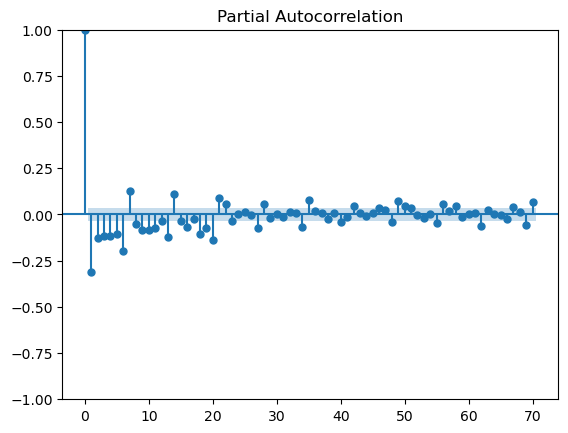

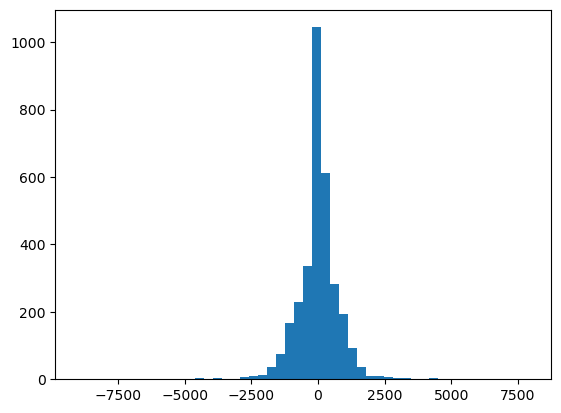

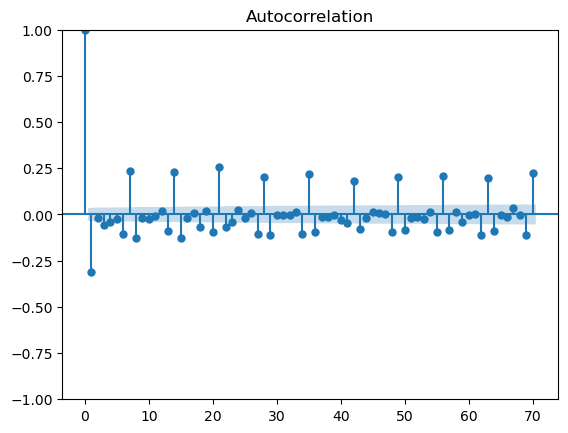

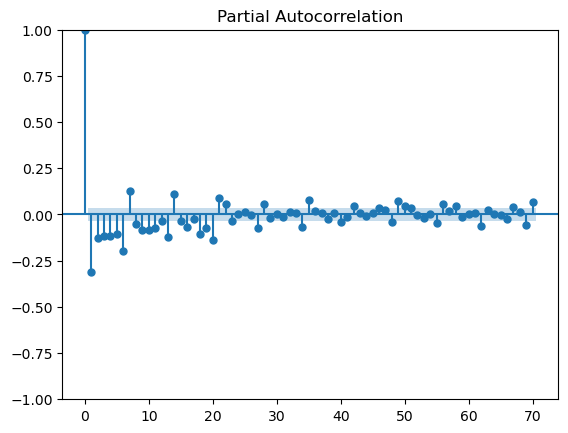

In [36]:
from statsmodels.tsa.statespace.tools import diff
check= diff(df2['Evening Peak Demand'], k_diff=1, k_seasonal_diff=None, seasonal_periods=365)

print('\n\n Adf test :Ho: Non-Stationary, H1: Stationary \n',adfuller(check))
#H0: Non-Stationary
#H1: stationary
print('\n\n KPSS test : Ho: Stationary, H1: Not Stationary   \n',kpss(check))
#H0: Stationary
#H1: Non-stationary

# The Shapiro-Wilk test
print('\n\n Shapiro Test: Ho: Data frm Normal Dist \n', shapiro(check))
#print(normaltest(dataset))

#H0: data from normal distribution
#H1: data not from normal distribution    
print('\n\n skewness: ',skew(list(check.values)))
print('\n\n kurtosis: ',kurtosis(list(check.values)))


plt.hist(check, bins=50)

plot_acf(check, lags=70  )
plot_pacf(check, lags=70, method='ols')

C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=45060.746, Time=0.04 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=40643.875, Time=0.10 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=43132.020, Time=0.57 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=54325.588, Time=0.02 sec


C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=40393.201, Time=0.34 sec


C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


...

 ARIMA(6,0,6)(0,0,0)[0] intercept   : AIC=39939.935, Time=8.00 sec


C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(8,0,6)(0,0,0)[0] intercept   : AIC=39880.140, Time=8.19 sec


C:\Users\dipayan\anaconda3\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


 ARIMA(7,0,5)(0,0,0)[0]             : AIC=inf, Time=5.92 sec

Best model:  ARIMA(7,0,5)(0,0,0)[0] intercept
Total fit time: 145.392 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2556
Model:               SARIMAX(7, 0, 5)   Log Likelihood              -19900.832
Date:                Sun, 15 Jun 2025   AIC                          39829.665
Time:                        23:36:34   BIC                          39911.511
Sample:                             0   HQIC                         39859.345
                               - 2556                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    282.3556     88.812      3.179      0.001     108.288    

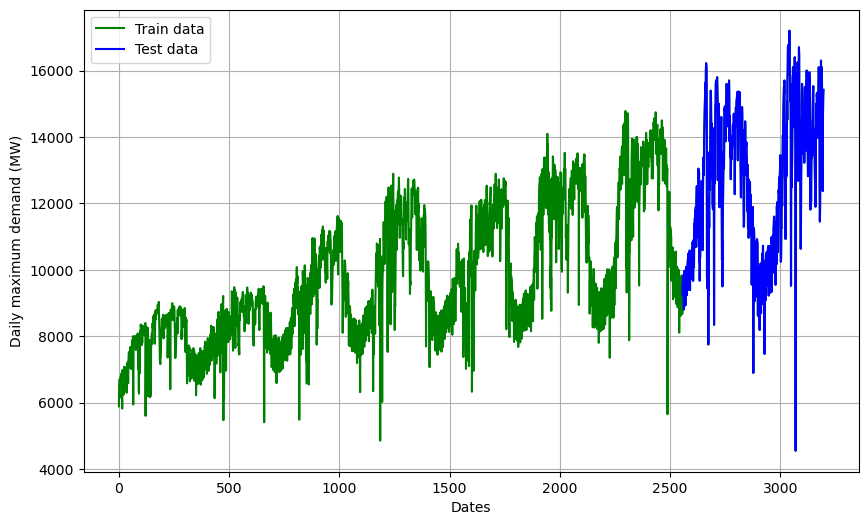

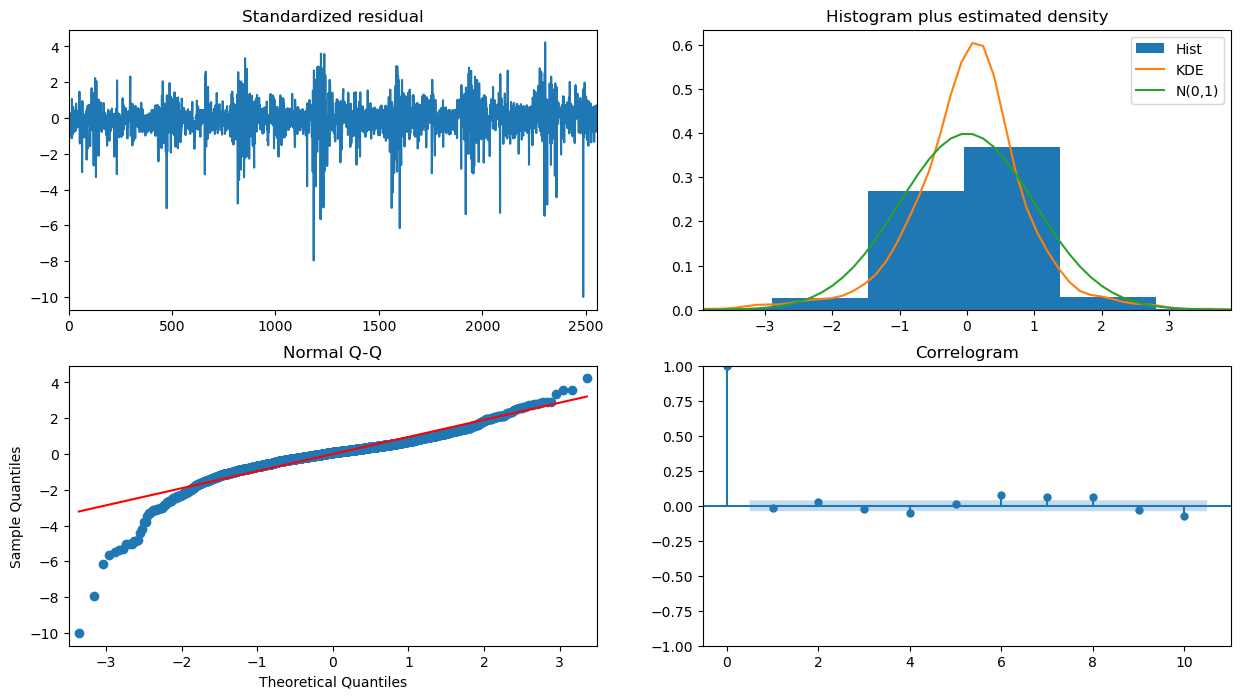

In [37]:
from statsmodels.tsa.arima.model import ARIMA
from pmdarima.arima import auto_arima, arima

train_data, test_data = df2[0:int(len(df2)*0.8)], df2[int(len(df2)*0.8):]
plt.figure(figsize=(10,6))
plt.grid(True)
plt.xlabel('Dates')
plt.ylabel('Daily maximum demand (MW)')
plt.plot(df2, 'green', label='Train data')
plt.plot(test_data, 'blue', label='Test data')
plt.legend()


result = seasonal_decompose(train_data, model='additive', extrapolate_trend='freq', period=365)
seasonal_adjusted= train_data['Evening Peak Demand'].values - result.seasonal



model_autoARIMA = auto_arima(seasonal_adjusted.astype(float), start_p=0, start_q=0,
test='adf',          # adftest to find optimal 'd'
max_p=10, max_q=10 , # maximum p and q
m=1,                 # frequency of series
d=None,              # let model determine 'd'
seasonal=True,       #  Seasonality
start_P=0, 
D=365, 
trace=True,
error_action='ignore',  
suppress_warnings=True, 
stepwise=True)
print(model_autoARIMA.summary())


model_autoARIMA.plot_diagnostics(figsize=(15,8))
plt.show()

C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:               seasonal   No. Observations:                 2556
Model:               ARIMA(15, 1, 12)   Log Likelihood              -19802.003
Date:                Sun, 15 Jun 2025   AIC                          39660.005
Time:                        23:39:28   BIC                          39823.688
Sample:                             0   HQIC                         39719.364
                               - 2556                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0627      0.383     -0.164      0.870      -0.812       0.687
ar.L2         -0.7513      0.339     -2.218      0.027      -1.415      -0.087
ar.L3         -0.0024      0.298     -0.008      0.9

<Figure size 640x480 with 0 Axes>

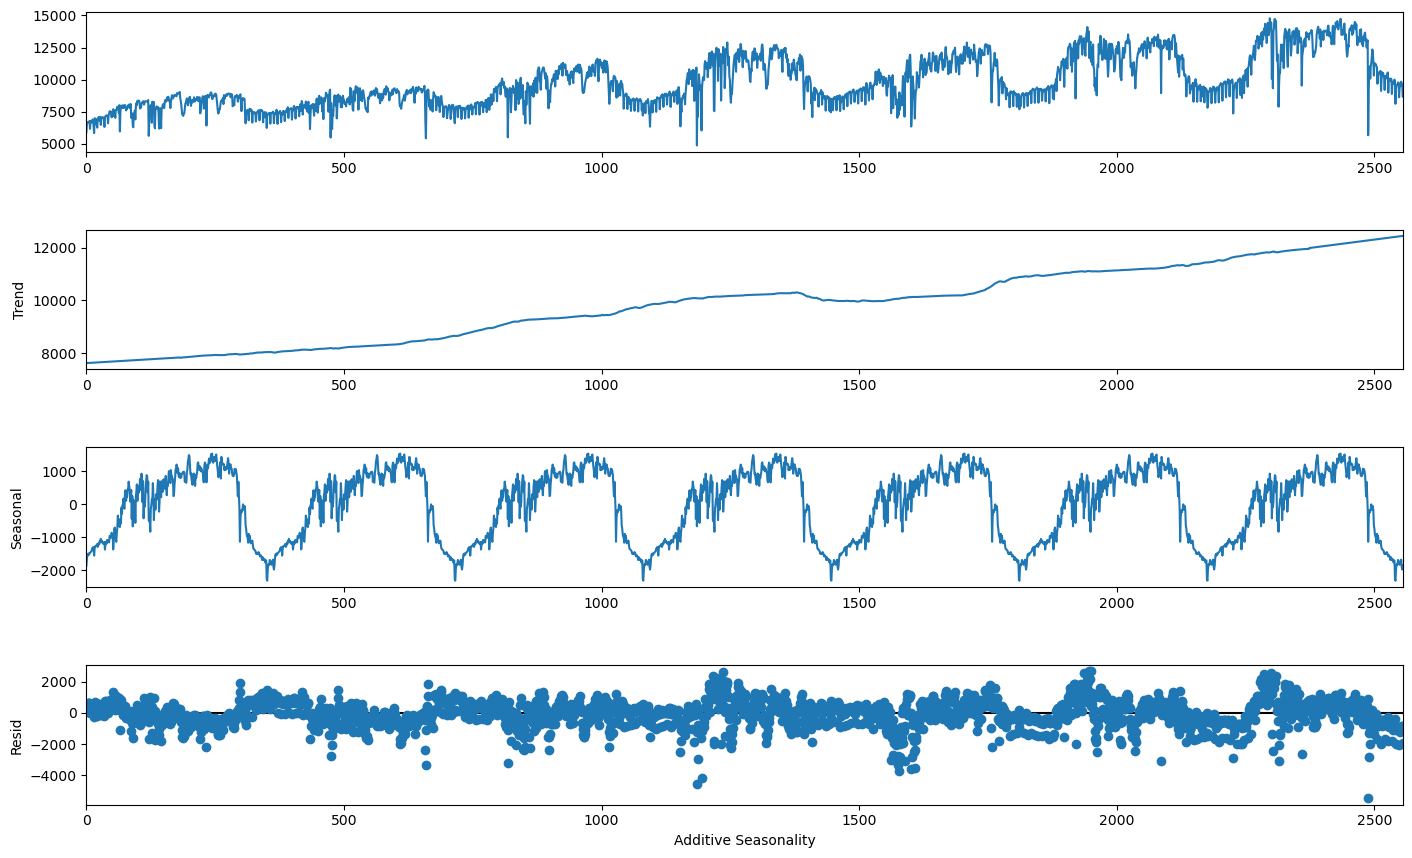

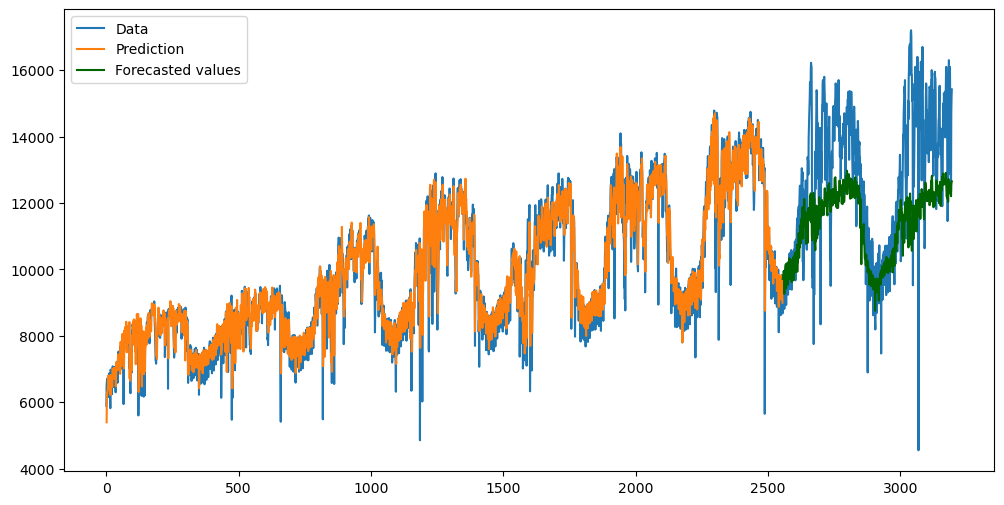

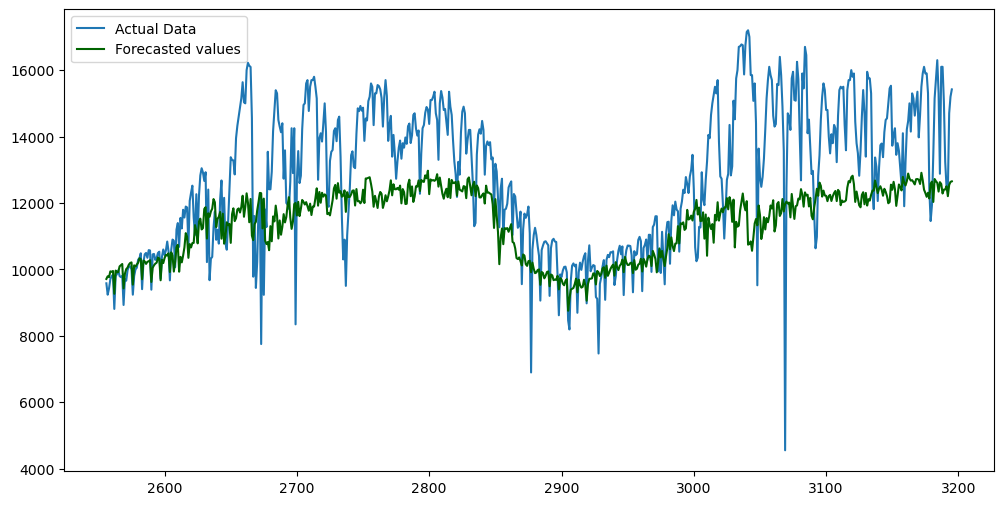

In [41]:
# Classical + ARIMA
result = seasonal_decompose(train_data, model='additive', extrapolate_trend='freq', period=365)
seasonal_adjusted= train_data['Evening Peak Demand'].values - result.seasonal



fig = plt.figure()  
fig = result.plot()  
fig.set_size_inches(16, 9)
fig=plt.xlabel("Additive Seasonality")


model=ARIMA(seasonal_adjusted.astype(float),order=(15,1,12))
fitted = model.fit()
print(fitted.summary())
n_test=len(test_data)
#print(n_test)
predict=fitted.predict()
forecasted=fitted.forecast(n_test)


n_train=len(train_data)
delta = n_train%365
print(delta)
forecasted_with_seasonality=forecasted+result.seasonal[delta:n_test+delta].values
forecast_Classical_ARIMA = forecasted_with_seasonality

plt.show()

plt.figure(figsize=([12,6]))
plt.plot(df2, label="Data")
plt.plot(predict[1:n_train]+result.seasonal[1:n_train], label="Prediction")

plt.plot(forecasted_with_seasonality, color='darkgreen', label="Forecasted values")
plt.legend()
plt.show()


plt.figure(figsize=([12,6]))
plt.plot(df2[n_train:], label="Actual Data")

plt.plot(forecasted_with_seasonality,color='darkgreen', label="Forecasted values")
plt.legend()
plt.show()

In [42]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score

trainData=train_data.values.astype(float)
testData=test_data.values.astype(float)

print("################  Result on train data ###################")

# Calculate training metrics
predictions=np.array(predict)
predictions=predictions.reshape([predictions.shape[0],1])
mse = mean_squared_error(trainData, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(trainData, predictions)
r2 = r2_score(trainData, predictions)
evs = explained_variance_score(trainData, predictions)
mape = np.mean(np.abs((trainData - predictions) / trainData)) * 100
mpe = np.mean((trainData - predictions) / trainData) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



print("################  Result on test data ###################")

# Calculate training metrics
forecast=np.array(forecasted_with_seasonality)
forecast=forecast.reshape([forecast.shape[0],1])
mse = mean_squared_error(testData, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(testData, forecast)
r2 = r2_score(testData, forecast)
evs = explained_variance_score(testData, forecast)
mape = np.mean(np.abs((testData - forecast) / testData)) * 100
mpe = np.mean((testData - forecast) / testData) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



################  Result on train data ###################
Root Mean Squared Error (RMSE): 1195.080758075193
Mean Squared Error (MSE): 1428218.018321578
Mean Absolute Error (MAE): 1045.3631956256804
R2 Score: 0.6205833953845024
Explained Variance Score: 0.6206111700997976
Mean Absolute Percentage Error (MAPE): 11.226809981225939
Mean Percentage Error (MPE): -1.3538349485587606
################  Result on test data ###################
Root Mean Squared Error (RMSE): 2054.323637030421
Mean Squared Error (MSE): 4220245.605661898
Mean Absolute Error (MAE): 1612.5445286324518
R2 Score: 0.07569117823294014
Explained Variance Score: 0.4794342436370792
Mean Absolute Percentage Error (MAPE): 11.864074881643042
Mean Percentage Error (MPE): 8.923990161447149


C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                    SARIMAX Results                                     
Dep. Variable:                                y   No. Observations:                 2556
Model:             ARIMA(2, 0, 2)x(1, 0, [], 7)   Log Likelihood              -20191.036
Date:                          Sun, 15 Jun 2025   AIC                          40396.072
Time:                                  23:41:09   BIC                          40436.996
Sample:                                       0   HQIC                         40410.913
                                         - 2556                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       9839.5408    770.609     12.769      0.000    8329.175    1.13e+04
ar.L1          1.6820      0.031     53.664      0.

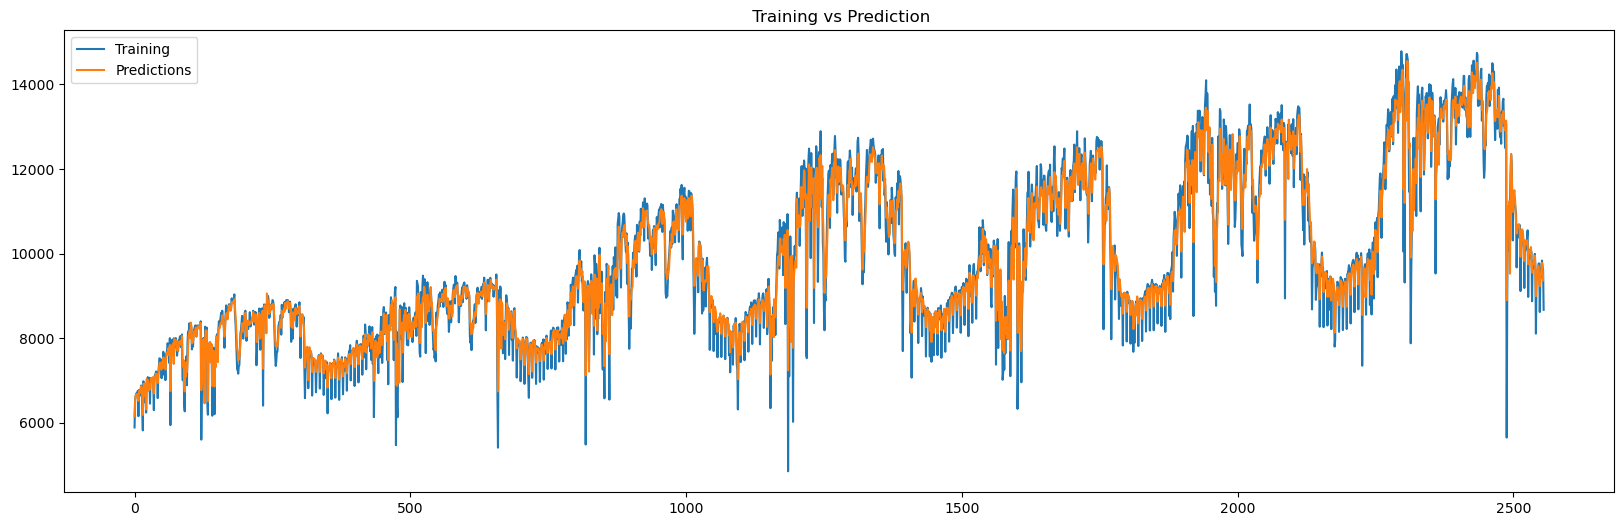

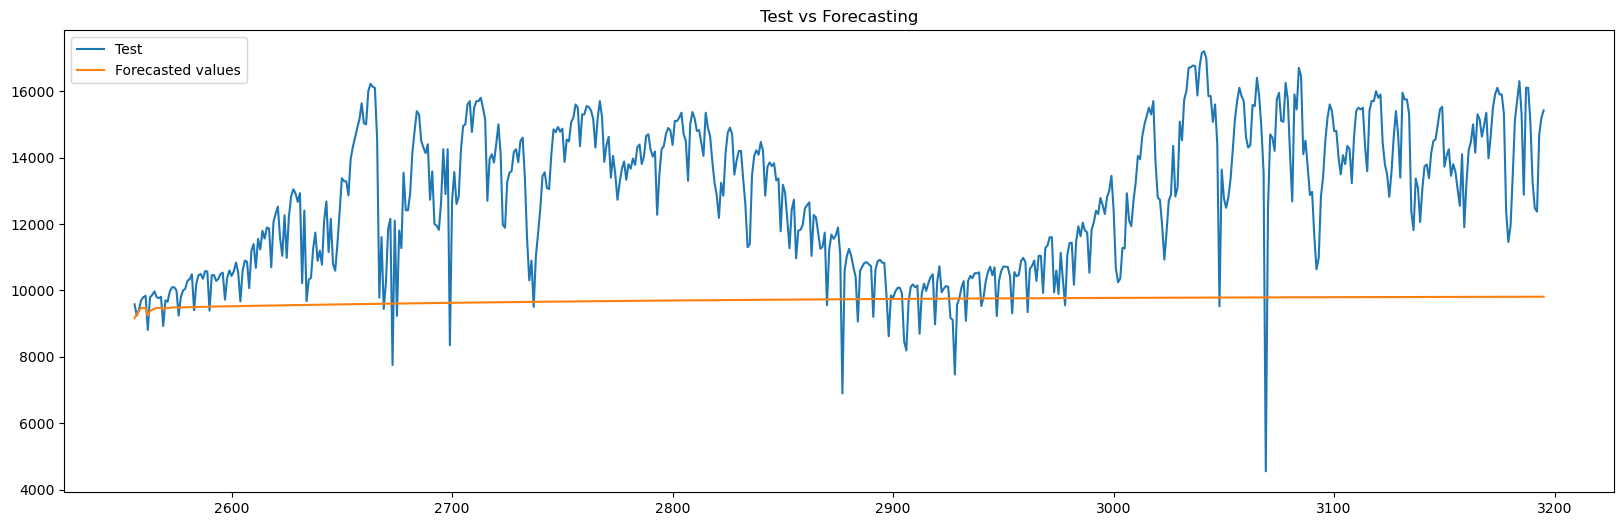

################  Result on train data ###################
Root Mean Squared Error (RMSE): 656.1161754369662
Mean Squared Error (MSE): 430488.4356700317
Mean Absolute Error (MAE): 428.06553835077074
R2 Score: 0.8856375857937229
Explained Variance Score: 0.8856398458912855
Mean Absolute Percentage Error (MAPE): 4.581741627827707
Mean Percentage Error (MPE): -0.4566687170363902
################  Result on test data ###################
Root Mean Squared Error (RMSE): 3727.4470834718877
Mean Squared Error (MSE): 13893861.760083083
Mean Absolute Error (MAE): 3160.2031470130546
R2 Score: -2.04300275226343
Explained Variance Score: 0.028909366279427307
Mean Absolute Percentage Error (MAPE): Evening Peak Demand    22.926002
dtype: float64
Mean Percentage Error (MPE): Evening Peak Demand    21.744667
dtype: float64


C:\Users\dipayan\anaconda3\lib\site-packages\numpy\core\fromnumeric.py:3462: FutureWarning: In a future version, DataFrame.mean(axis=None) will return a scalar mean over the entire DataFrame. To retain the old behavior, use 'frame.mean(axis=0)' or just 'frame.mean()'
  return mean(axis=axis, dtype=dtype, out=out, **kwargs)


In [43]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score

trainData=train_data.values.astype(float)


model_arima = ARIMA(trainData, order=(2,0,2), seasonal_order=(1, 0, 0, 7))

#fitted = model.fit(disp=-1)
fitted = model_arima.fit()

print(fitted.summary())

n_test=len(test_data)
print(n_test)
predict=fitted.predict()
forecasted=fitted.forecast(n_test)

#print(predict)
#print(forecasted)

plt.figure(figsize=(20,6))
plt.plot(trainData, label='Training')
plt.plot(predict[1:], label='Predictions')
plt.legend(loc='best')
plt.title(" Training vs Prediction")
plt.show()


plt.figure(figsize=(20,6))
plt.plot(test_data, label='Test')
plt.plot(test_data.index, forecasted, label='Forecasted values')
plt.legend(loc='best')
plt.title("Test vs Forecasting")
plt.show()



print("################  Result on train data ###################")

# Calculate training metrics
predictions=np.array(predict)
predictions=predictions.reshape([predictions.shape[0],1])
mse = mean_squared_error(trainData, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(trainData, predictions)
r2 = r2_score(trainData, predictions)
evs = explained_variance_score(trainData, predictions)
mape = np.mean(np.abs((trainData - predictions) / trainData)) * 100
mpe = np.mean((trainData - predictions) / trainData) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



print("################  Result on test data ###################")

# Calculate training metrics
forecast=np.array(forecasted)
forecast=forecast.reshape([forecast.shape[0],1])
mse = mean_squared_error(test_data, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data, forecast)
r2 = r2_score(test_data, forecast)
evs = explained_variance_score(test_data, forecast)
mape = np.mean(np.abs((test_data - forecast) / test_data)) * 100
mpe = np.mean((test_data - forecast) / test_data) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



In [ ]:
plt.figure(figsize=(20,6))
plt.plot(test, label='Test')
plt.plot(predictions, label='Predictions')
plt.legend(loc='best')
plt.show()

In [ ]:
for i in range(2859):
    #print(df2.loc[i].astype(float))
    if np.isnan(df2.loc[i])==True:
        print(i)

In [46]:
# Fit the model
import statsmodels.api as sm
from statsmodels.tsa.exponential_smoothing.ets import ETSModel, SARIMAX

mod = sm.tsa.statespace.SARIMAX(df2.values[:,0].astype(float), trend='c', order=(1,0,0))

res = mod.fit(disp=False)
print(res.summary())

ImportError: cannot import name 'SARIMAX' from 'statsmodels.tsa.exponential_smoothing.ets' (C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\tsa\exponential_smoothing\ets.py)

[ 7760.06423813  8189.35367419  8161.11856557 ... 11577.17832263
 11617.99452533 10540.06423813]


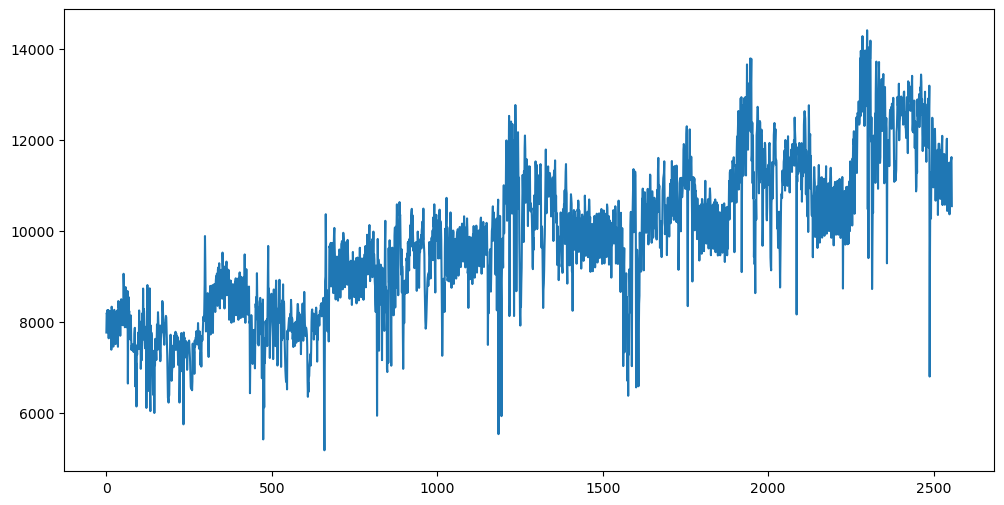

In [50]:
print(seasonal_adjusted.values.astype(float))
plt.figure(figsize=[12,6])
plt.plot(seasonal_adjusted.values.astype(float))

1


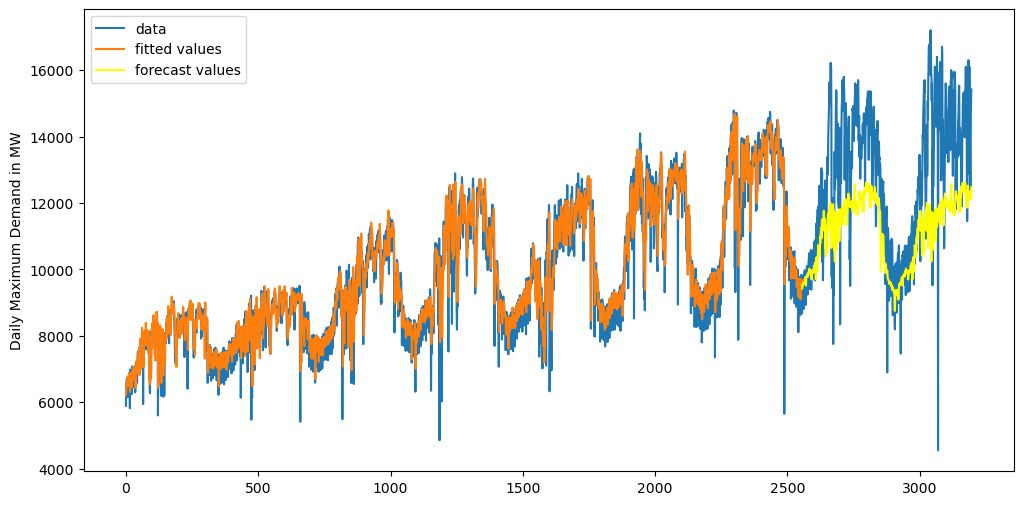

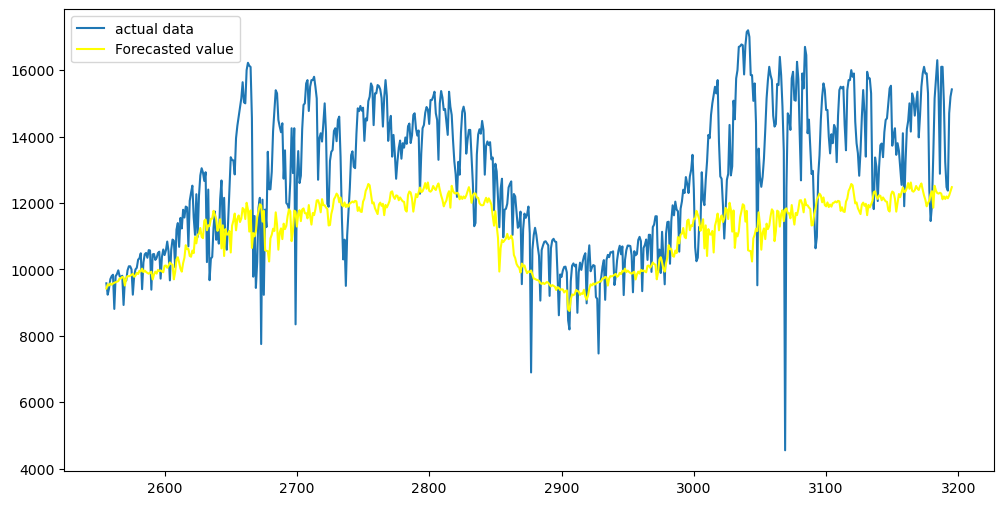

                                 ETS Results                                  
Dep. Variable:                      y   No. Observations:                 2556
Model:                       ETS(ANN)   Log Likelihood              -20154.966
Date:                Sun, 15 Jun 2025   AIC                          40315.932
Time:                        23:43:58   BIC                          40333.471
Sample:                             0   HQIC                         40322.292
                               - 2556   Scale                       413673.336
Covariance Type:               approx                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
smoothing_level     0.4698      0.024     19.672      0.000       0.423       0.517
initial_level    8076.4236    545.396     14.808      0.000    7007.466    9145.381
Ljung-Box (Q):                  

In [51]:
# Classical + ETS 
from statsmodels.tsa.exponential_smoothing.ets import ETSModel #, SARIMAX

result = seasonal_decompose(train_data, model='additive', extrapolate_trend='freq', period=365)
seasonal_adjusted= train_data['Evening Peak Demand'].values - result.seasonal




model=ETSModel(seasonal_adjusted.values.astype(float))
fit = model.fit(maxiter=10000)
predict= fit.fittedvalues[0:]+result.seasonal

forecasted_ETS=fit.forecast(n_test)

n_train=len(train_data)
delta = n_train%365
print(delta)

forecasted_with_seasonality=forecasted_ETS+result.seasonal[delta:n_test+delta].values

forecast_Classical_ETS= forecasted_with_seasonality

plt.figure(figsize=(12,6))
plt.plot(df2[0:],label="data")
#fit.fittedvalues.plot(label="statsmodels fit")
plt.plot(predict, label="fitted values")
plt.plot(df2[-n_test:].index, forecasted_with_seasonality,label="forecast values", color='YELLOW')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()



plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],test_data, label='actual data')
#plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecasted_with_seasonality, label='Forecasted value',color='YELLOW')
plt.legend()
plt.show()



print(fit.summary())



In [52]:
print("################  Result on train data ###################")

# Calculate training metrics
predictions=np.array(predict)
predictions=predictions.reshape([predictions.shape[0],1])
mse = mean_squared_error(trainData[:,0], predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(trainData, predictions)
r2 = r2_score(trainData, predictions)
evs = explained_variance_score(trainData, predictions)
mape = np.mean(np.abs((trainData - predictions) / trainData)) * 100
mpe = np.mean((trainData - predictions) / trainData) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



print("################  Result on test data ###################")

# Calculate training metrics
forecast=np.array(forecasted_with_seasonality)
forecast=forecast.reshape([forecast.shape[0],1])
mse = mean_squared_error(testData, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(testData, forecast)
r2 = r2_score(testData, forecast)
evs = explained_variance_score(testData, forecast)
mape = np.mean(np.abs((testData - forecast) / testData)) * 100
mpe = np.mean((testData - forecast) / testData) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



################  Result on train data ###################
Root Mean Squared Error (RMSE): 643.1744209206311
Mean Squared Error (MSE): 413673.3357265891
Mean Absolute Error (MAE): 447.7495377233049
R2 Score: 0.8901046405745532
Explained Variance Score: 0.8901062967590434
Mean Absolute Percentage Error (MAPE): 4.802455312946488
Mean Percentage Error (MPE): -0.356788574246931
################  Result on test data ###################
Root Mean Squared Error (RMSE): 2230.5920724398743
Mean Squared Error (MSE): 4975540.993631613
Mean Absolute Error (MAE): 1806.5511619007455
R2 Score: -0.08973194055516376
Explained Variance Score: 0.46579537094818046
Mean Absolute Percentage Error (MAPE): 13.329970574165511
Mean Percentage Error (MPE): 10.789229331372372


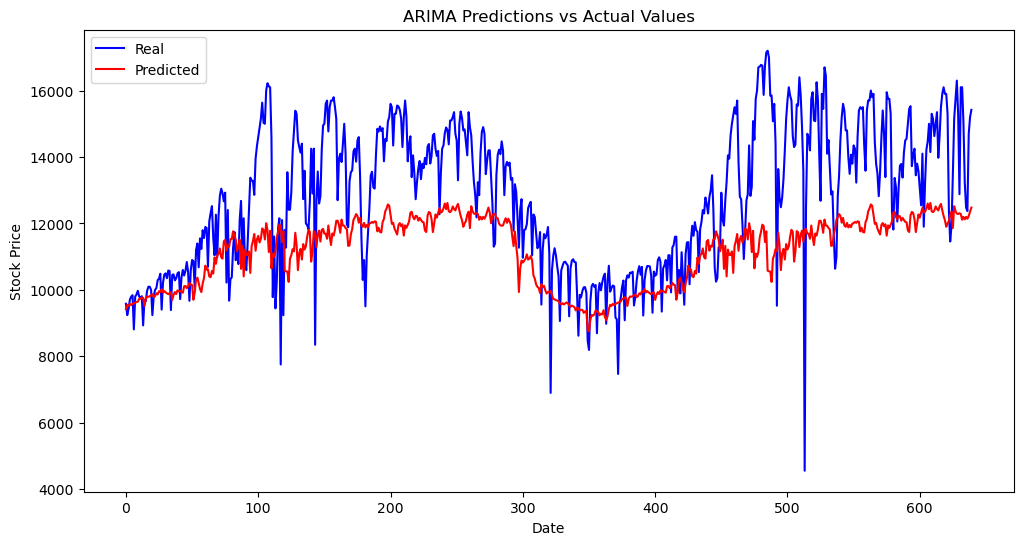

In [53]:
import matplotlib.pyplot as plt
size=1
plt.figure(figsize=(12, 6), dpi=100)
#plt.plot(train_data.iloc[size:,:].index, test, label='Real')
#plt.plot(test_data.iloc[size:].index, test, color='blue', label='Real')
plt.plot(testData, color='blue', label='Real')

#plt.plot(train_data.iloc[size:,:].index, predictions, color='red', label='Predicted')
#plt.plot(test_data.iloc[size:].index, predictions, color='red', label='Predicted')
plt.plot(forecast, color='red', label='Predicted')

plt.title('ARIMA Predictions vs Actual Values')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\dipayan\anaconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2556
Model:                 ARIMA(8, 0, 6)   Log Likelihood              -20116.489
Date:                Sun, 15 Jun 2025   AIC                          40264.978
Time:                        23:59:34   BIC                          40358.517
Sample:                             0   HQIC                         40298.899
                               - 2556                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       9839.5877   1.48e+04      0.664      0.507   -1.92e+04    3.89e+04
ar.L1         -0.3422      0.023    -14.995      0.000      -0.387      -0.298
ar.L2          0.0063      0.015      0.419      0.6

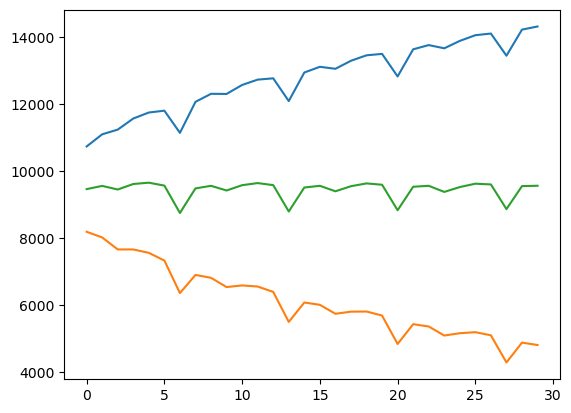

In [80]:
model = ARIMA(np.asarray(train_data.astype(float)), order=(8,0, 6))

fitted = model.fit()

print(fitted.summary())

SEE=fitted.get_forecast(30, alpha=0.05)
print(SEE.summary_frame())

fc, se, conf_L, conf_U= SEE.summary_frame()


pre=SEE.summary_frame()

plt.plot(pre.mean_ci_upper)
plt.plot(pre.mean_ci_lower)
plt.plot(pre['mean'])
print(pre['mean'])

0      9460.212310
1      9556.276461
2      9448.171448
3      9612.863305
4      9651.809342
          ...     
635    9604.483889
636    9436.840380
637    9670.532433
638    9653.006380
639    9496.222640
Name: mean, Length: 640, dtype: float64


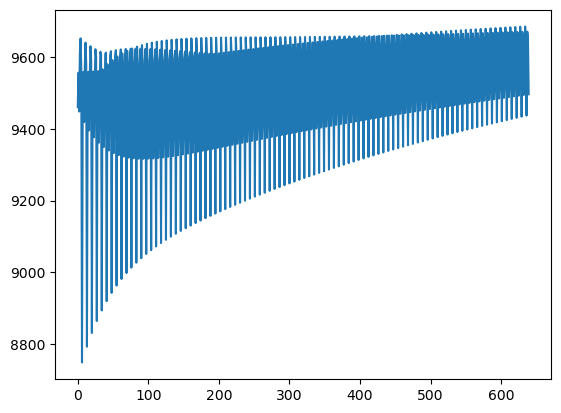

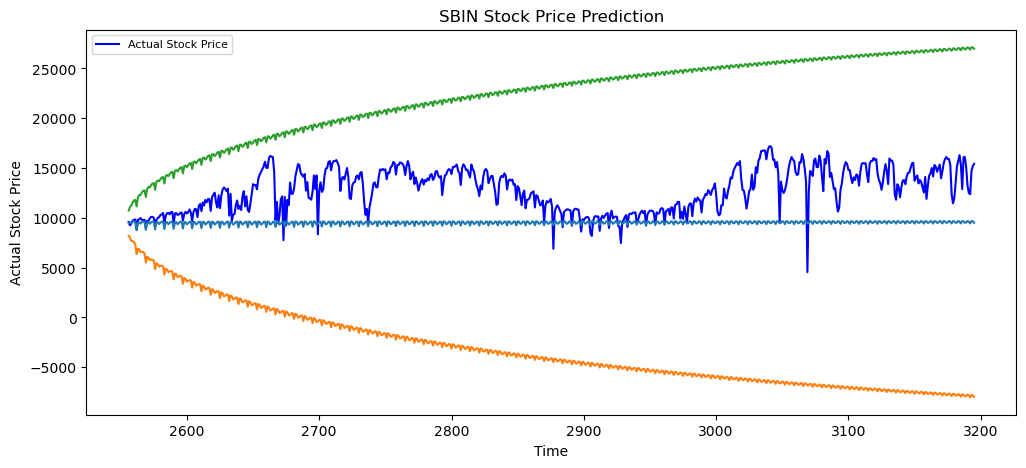

In [83]:
FORECAST = fitted.get_forecast(len(test_data), alpha=0.05).summary_frame() # 95% confidence
fc=FORECAST['mean']
print(fc)
plt.plot(fc)
se=FORECAST['mean_se']
conf_L=FORECAST['mean_ci_lower']
conf_U=FORECAST['mean_ci_upper']
fc_series = pd.Series(fc[1:], index=test_data.index)
#lower_series = pd.Series(conf[:, 0], index=test_data.index)
#upper_series = pd.Series(conf[:, 1], index=test_data.index)
lower_series = pd.Series(conf_L, index=test_data.index)
upper_series = pd.Series(conf_U, index=test_data.index)
plt.figure(figsize=(12,5), dpi=100)
#plt.plot(train_data, label='training')
plt.plot(test_data, color = 'blue', label='Actual Stock Price')
#plt.plot(fc_series, color = 'orange',label='Predicted Stock Price')
plt.plot(test_data.index,fc)
plt.plot(test_data.index,conf_L)
plt.plot(test_data.index,conf_U)


plt.fill_between(lower_series.index, lower_series, upper_series, 
                 color='k', alpha=.10)
plt.title('SBIN Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('Actual Stock Price')
plt.legend(loc='upper left', fontsize=8)

plt.show()

In [84]:
print(np.array(predictions).shape)

(2556, 1)


In [85]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score

test=test_data
predictions=np.array(predictions)
predictions=predictions.reshape([predictions.shape[0],1])
mse = mean_squared_error(test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test, predictions)

r2 = r2_score(test, predictions)
evs = explained_variance_score(test, predictions)

mape = np.mean(np.abs((test, predictions) / test)) * 100
mpe = np.mean((test, predictions) / test) * 100

print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")

ValueError: Found input variables with inconsistent numbers of samples: [640, 2556]

numpy.ndarray

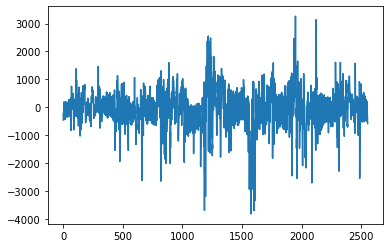

In [69]:
plt.plot(stlf_res.result.resid)

type(residuals.values)

############# STL + ARIMA (15,1,12) ##############


C:\Users\dipu_\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\dipu_\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\dipu_\anaconda3\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


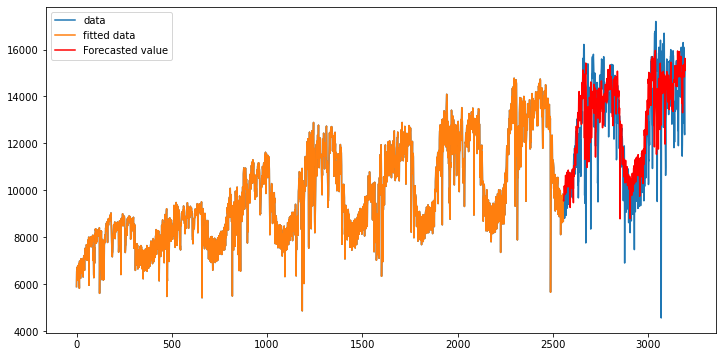

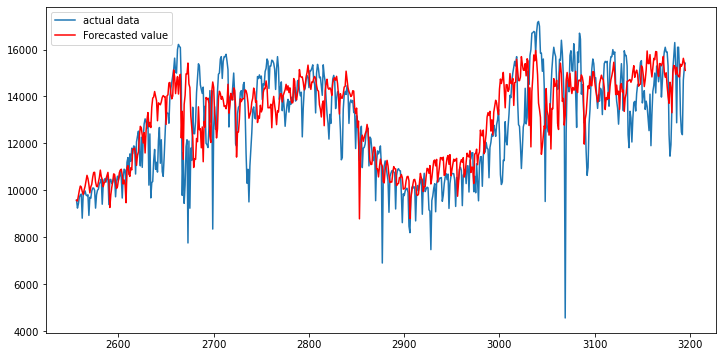

################  Result on test data ###################
Root Mean Squared Error (RMSE): 1517.611179110755
Mean Squared Error (MSE): 2303143.690961936
Mean Absolute Error (MAE): 1104.6700356335677
R2 Score: 0.49557058278853805
Explained Variance Score: 0.5134905846879299
Mean Absolute Percentage Error (MAPE): 9.22732975253826
Mean Percentage Error (MPE): -3.6178350110215556
                    STL Decomposition and SARIMAX Results                     
Dep. Variable:                      y   No. Observations:                 2556
Model:               ARIMA(15, 1, 12)   Log Likelihood              -19315.563
Date:                Thu, 07 Aug 2025   AIC                          38689.127
Time:                        16:36:04   BIC                          38858.655
Sample:                             0   HQIC                         38750.606
                               - 2556                                         
Covariance Type:                  opg                                

In [109]:
# STL + ARIMA + Non-Linear Model

print("############# STL + ARIMA (15,1,12) ##############")

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.forecasting.stl import STLForecast
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
import numpy as np


stlf = STLForecast(train_data, ARIMA, model_kwargs=dict(order=(15, 1, 12), trend="t"), period=365)
stlf_res = stlf.fit()

forecast = stlf_res.forecast(640) 
forecast_STL_ARIMA=forecast


plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']], label='data')
plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast, color='red',label='Forecasted value')
plt.legend()
plt.show()

plt.figure(figsize=([12,6]))
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],test_data, label='actual data')
#plt.plot(df2[['Evening Peak Demand']].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2[['Evening Peak Demand']].index[int(len(df2)*0.8):],forecast,color='red', label='Forecasted value')
plt.legend()
plt.show()







print("################  Result on test data ###################")

# Calculate training metrics
#forecast=np.array(forecasted_with_seasonality)
#forecast=forecast.reshape([forecast.shape[0],1])
mse = mean_squared_error(test_data, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data, forecast)
r2 = r2_score(test_data, forecast)
evs = explained_variance_score(test_data, forecast)
mape = np.mean(np.abs((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values)) * 100
mpe = np.mean((test_data['Evening Peak Demand'].values - forecast.values) / test_data['Evening Peak Demand'].values) * 100

print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")

print(stlf_res.summary())



## ML nonlinear Model



0       -449.301049
1       -209.653633
2       -223.901554
3       -268.610349
4       -334.517095
           ...     
3191   -2813.314471
3192   -3014.494376
3193    -928.634242
3194    -238.719458
3195     306.015576
Length: 3196, dtype: object

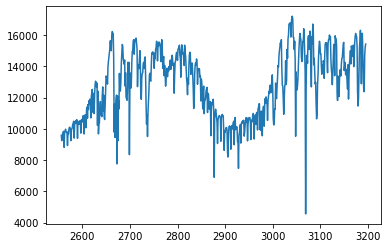

In [111]:
test_data1=df2[int(len(df2)*0.8):]
plt.plot(test_data1)

residuals_training = stlf_res.result.resid
residuals_test = test_data1['Evening Peak Demand'] - forecast_STL_ARIMA

residuals= residuals_training.append(residuals_test)
residuals

(3196, 1)


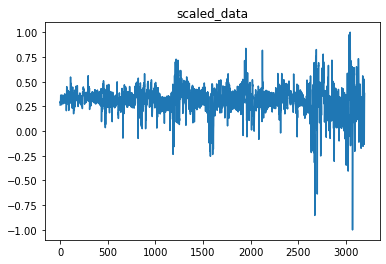

2557
(2527, 30, 1)
(639, 30, 1)
(0,)
(2527, 30, 1)
(2527, 0, 1)
(639, 1)
Model: "model_4"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_5 (InputLayer)        [(None, 30, 1)]              0         []                            
                                                                                                  
 conv1d_8 (Conv1D)           (None, 16, 15)               240       ['input_5[0][0]']             
                                                                                                  
 conv1d_9 (Conv1D)           (None, 2, 15)                3390      ['conv1d_8[0][0]']            
                                                                                                  
 reshape_12 (Reshape)        (None, 30, 1)                0         ['conv1d_9[0][0]']            
                   

In [186]:
#residuals = stlf_res.result.resid

residuals_training = stlf_res.result.resid
residuals_test = test_data1['Evening Peak Demand'] - forecast_STL_ARIMA

residuals= residuals_training.append(residuals_test)


# Scale the data
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import math

#dataset=df2.values
scaler = MinMaxScaler(feature_range=(-1,1))
scaled_data=scaler.fit_transform(residuals.values.reshape(-1,1))

print(scaled_data.shape)

plt.plot(scaled_data)
plt.title('scaled_data')
plt.show()



training_data_len=math.ceil(len(residuals)* 0.8)
print(training_data_len)



train_data=scaled_data[0:training_data_len,:]

x_train=[]
y_train=[]
y_train_long=[]

feature_len=30
forecast_len=0

for i in range(feature_len, len(train_data)-forecast_len):
    #x_train.append(train_data[i-60:i, 0])
    #y_train.append(train_data[i,0])
    x_train.append(train_data[i-feature_len:i, :])
    y_train.append(train_data[i,:])
    y_train_long.append(train_data[i:i+forecast_len,:])
    
    #if i <=61:
        #print(x_train)
        #print(y_train)

        



        
test_data=scaled_data[training_data_len -feature_len: , :]

x_test=[]
y_test= residuals.values.reshape(-1,1)[training_data_len:, :]
y_test_long=[]




for i in range (feature_len, len(test_data)-forecast_len):
    #x_test.append(test_data[i-60:i,0])
    x_test.append(test_data[i-feature_len:i,:])
   
    #y_test_long.append(dataset [i:i+forecast_len, :])





x_train, y_train, y_train_long = np.array(x_train), np.array(y_train), np.array(y_train_long)
print(x_train.shape)


# convert data to numpy array 

x_test, y_test_long = np.array(x_test), np.array(y_test_long)
print(x_test.shape)
print(y_test_long.shape)



x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1],1))
#x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1],3))

print(x_train.shape)
print(y_train_long.shape)

x_test=np.reshape(x_test,(x_test.shape[0], x_test.shape[1],1))
#x_test=np.reshape(x_test,(x_test.shape[0], x_test.shape[1],3))

print(y_test.shape)

# CNN LSTM - Residual-Multiple _Single Forecast

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate
from keras import regularizers
from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x= Conv1D(15, 15, activation='relu')(inputs)
x = Conv1D(15, 15,  activation='relu')(x)
x = Reshape((feature_len,1))(x)
x1= Concatenate()([x,inputs])
x = LSTM(feature_len, dropout=0.1, return_sequences = True)(x1)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x2= x+x1
x = LSTM(feature_len, dropout=0.1, return_sequences = True)(x2)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x3=Concatenate()([x,inputs])
#x = LSTM(feature_len, return_sequences = True)(x3)
x = LSTM(feature_len, dropout=0.1, return_sequences = False)(x3)
x = Dense(20, activation="relu")(x)
x = Dropout(0.1)(x)
outputs = Dense(1, activation="tanh")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)





20/20 [==============================] - 1s 12ms/step
(639, 1)
(639,)
(0,)


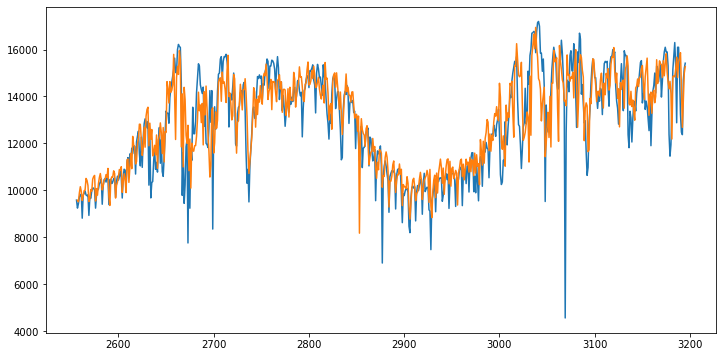

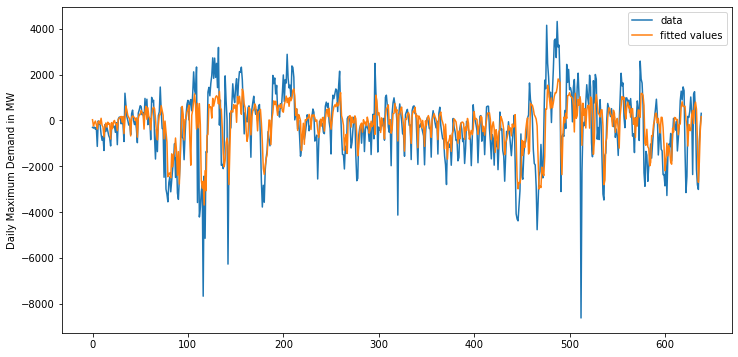

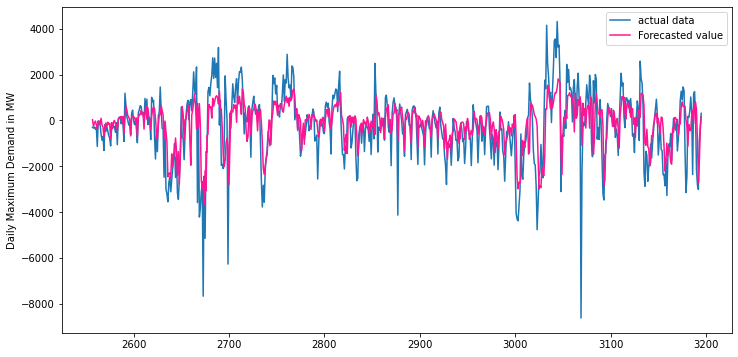

Mean Squared Error (MSE): 1361290.1203204289
Root-Mean Squared Error (RMSE): 1166.74338237696
Mean Absolute Error (MAE): 791.8077528946
R2 Score: -36.55495360492969
Explained Variance Score: 0.705581299652561
Mean Absolute Percentage Error (MAPE): 363.18550560286843


In [187]:
predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test_long.shape)

forecast_NON_linera_model=predictions

train_data1=df2[0:int(len(df2)*0.8)]

#final_forecast= stlf_res.result.trend[-511:] + stlf_res.result.seasonal[-511:] + forecast_NON_linera_model

final_forecast= forecast_STL_ARIMA[1:] + forecast_NON_linera_model

plt.figure(figsize=[12,6])
plt.plot(test_data1)
plt.plot(final_forecast)
plt.show()

plt.figure(figsize=(12,6))
plt.plot(y_test,label="data")


plt.plot(predictions, label="fitted values")
#plt.plot(df2[-len(y_test):-30].index, predictions ,label="forecast values", color='deeppink')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()


#plt.plot(predictions[0:,1])
plt.figure(figsize=[12,6])
#plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], df2[['Evening Peak Demand']][-len(predictions):], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], y_test, label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], predictions,label='Forecasted value', color="deeppink")
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score #, root_mean_squared_log_error
from sktime.performance_metrics.forecasting import mean_absolute_scaled_error


# Calculate test metrics
mse = mean_squared_error(test_data1[1:], final_forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test_data1[1:], final_forecast)

r2 = r2_score(test_data1[1:], predictions)
evs = explained_variance_score(test_data1[1:], final_forecast)
#rmsle= root_mean_squared_log_error(y_test,predictions)
mase = mean_absolute_scaled_error(test_data1[1:],final_forecast, y_train=y_train, sp=365)

#mape = np.mean(np.abs((test_data1[1:,0] - final_forecast) / test_data1)) * 100
#mpe = np.mean((test_data1[1:,0] - final_forecast) / test_data1) * 100
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
#print(f"Mean Percentage Error (MPE): {mpe}")
#print(f"Mean Percentage Error (MASE): {mase}")
#print(f"Mean Percentage Error (RMSLE): {rmsle}")

<class 'numpy.ndarray'>


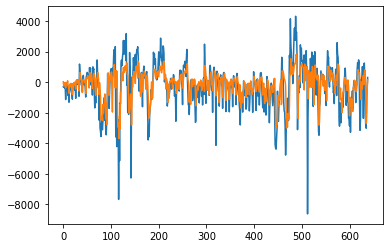

In [188]:

plt.plot(y_test)
#predictionsss = model.predict(x_train)
#plt.plot(y_train)
plt.plot(predictions)
print(type(residuals_test.values.to_numpy()))

In [86]:
# Scale the data
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import math

dataset=df2.values
scaler = MinMaxScaler(feature_range=(0,1))
scaled_data=scaler.fit_transform(dataset)

print(scaled_data.shape)

(3196, 1)


In [87]:
# Create the training dataset


training_data_len=math.ceil(len(dataset)* 0.8)
print(training_data_len)



train_data=scaled_data[0:training_data_len,:]

x_train=[]
y_train=[]
y_train_long=[]

feature_len=30
forecast_len=0

for i in range(feature_len, len(train_data)-forecast_len):
    #x_train.append(train_data[i-60:i, 0])
    #y_train.append(train_data[i,0])
    x_train.append(train_data[i-feature_len:i, :])
    y_train.append(train_data[i,:])
    y_train_long.append(train_data[i:i+forecast_len,:])
    
    #if i <=61:
        #print(x_train)
        #print(y_train)

        
# create Test dataset


        
test_data=scaled_data[training_data_len -feature_len: , :]

x_test=[]
y_test= dataset [training_data_len:, :]
y_test_long=[]




for i in range (feature_len, len(test_data)-forecast_len):
    #x_test.append(test_data[i-60:i,0])
    x_test.append(test_data[i-feature_len:i,:])
   
    y_test_long.append(dataset [i:i+forecast_len, :])


    
#convert x_train and y_train to numpy array


x_train, y_train, y_train_long = np.array(x_train), np.array(y_train), np.array(y_train_long)
print(x_train.shape)


# convert data to numpy array 

x_test, y_test_long = np.array(x_test), np.array(y_test_long)
print(x_test.shape)
print(y_test_long.shape)



2557
(2527, 30, 1)
(639, 30, 1)
(639, 0, 1)


In [88]:
#reshape the data

x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1],1))
#x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1],3))

print(x_train.shape)
print(y_train_long.shape)

x_test=np.reshape(x_test,(x_test.shape[0], x_test.shape[1],1))
#x_test=np.reshape(x_test,(x_test.shape[0], x_test.shape[1],3))

print(y_test.shape)



(2527, 30, 1)
(2527, 0, 1)
(639, 1)


In [89]:
## LSTM-Transformer-Dense

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = LSTM(feature_len, return_sequences = True, input_shape = (feature_len,3))(inputs)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x = Dropout(0.1)(x)
x = transformer_encoder(x, head_size=feature_len*2, num_heads=5, ff_dim=10, dropout=0.15)
x = GlobalAveragePooling1D(data_format='channels_first')(x)
x = Dropout(0.1)(x)
x = Dense(feature_len, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)




Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 30, 1)]      0           []                               
                                                                                                  
 lstm (LSTM)                    (None, 30, 30)       3840        ['input_1[0][0]']                
                                                                                                  
 lstm_1 (LSTM)                  (None, 30)           7320        ['lstm[0][0]']                   
                                                                                                  
 reshape (Reshape)              (None, 30, 1)        0           ['lstm_1[0][0]']                 
                                                                                              

20/20 [==============================] - 0s 10ms/step
(639, 1)
(639,)
(639, 1)


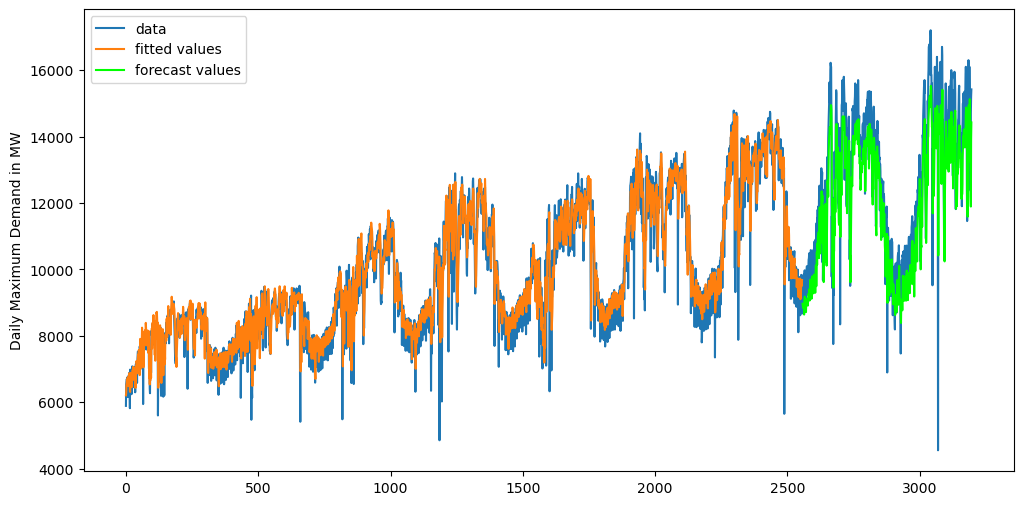

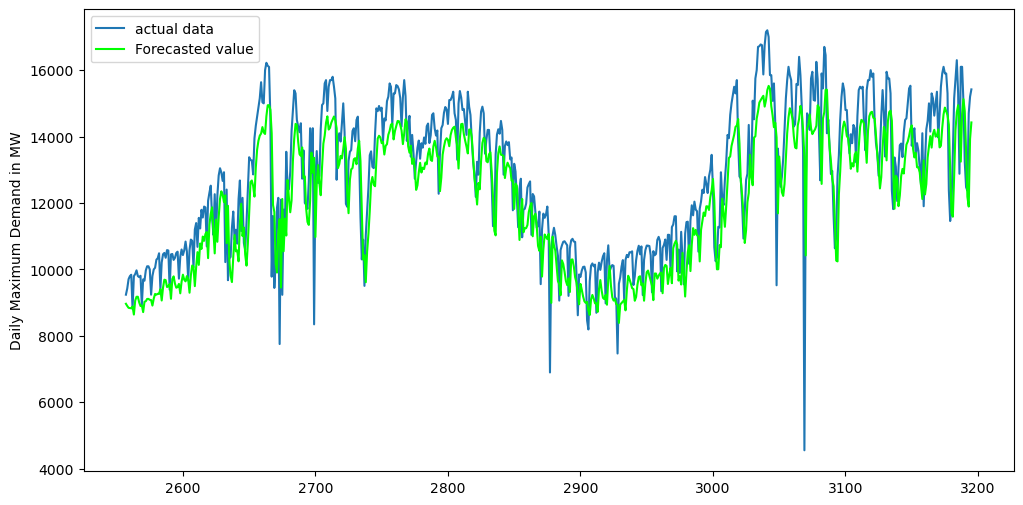

Mean Squared Error (MSE): 1462224.875
Root-Mean Squared Error (RMSE): 1209.2249067067714
Mean Absolute Error (MAE): 986.5889892578125
R2 Score: 0.679124116897583
Explained Variance Score: 0.7753602676572591
Mean Absolute Percentage Error (MAPE): 7.95978473739193
Mean Percentage Error (MPE): 5.342846590295835
Mean Percentage Error (MASE): 11314.950605740323
Mean Percentage Error (RMSLE): 0.10487473756074905


In [98]:
# sklearn version was 0.24.1
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score , root_mean_squared_log_error
from sktime.performance_metrics.forecasting import mean_absolute_scaled_error


# Get the models predicted demand in MW values

predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test.shape)

forecast_LSTM_mTrans_MLP=predictions


plt.figure(figsize=(12,6))
plt.plot(df2[0:],label="data")


plt.plot(predict, label="fitted values")
plt.plot(df2[-len(y_test):].index, predictions ,label="forecast values", color='lime')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()


#plt.plot(predictions[0:,1])
plt.figure(figsize=[12,6])
#plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], df2[['Evening Peak Demand']][-len(predictions):], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], y_test, label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], predictions,label='Forecasted value', color="lime")
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()



# Calculate test metrics
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)

r2 = r2_score(y_test, predictions)
evs = explained_variance_score(y_test, predictions)
rmsle= root_mean_squared_log_error(y_test,predictions)
mase = mean_absolute_scaled_error(y_test,predictions, y_train=y_train, sp=365)

mape = np.mean(np.abs((y_test[:,0] - predictions) / y_test)) * 100
mpe = np.mean((y_test[:,0] - predictions) / y_test) * 100
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")
print(f"Mean Percentage Error (MASE): {mase}")
print(f"Mean Percentage Error (RMSLE): {rmsle}")

In [137]:
sum=0
MASEnaive=np.mean(np.abs(y_train[365:]-y_train[:-365]))
MAE= np.mean(np.abs(y_test[:,0]-forecast_LSTM_mTrans_MLP))

print(MAE/MASEnaive)



11314.950605740323


In [119]:
def RMSLE(y_test, y_pred):   
    rmsle=np.sqrt(np.mean(np.array(np.log(y_test+1)-np.log(y_pred+1))**2))
    return rmsle

def MASE(y_test, y_pred, y_train, period):
    MASE_naive=np.mean(np.abs(y_train[period:]-y_train[:-period]))
    MAE= np.mean(np.abs(y_test[:,0]-forecast_LSTM_mTrans_MLP))
    return MAE/MASE_naive
    
    

In [159]:
print (RMSLE(np.array(y_test[:,0].tolist()),forecast_LSTM_mTrans_MLP))

print (MASE(y_test, forecast_LSTM_mTrans_MLP, y_train, period=365))
#print(np.log(np.array(y_test.tolist())))

0.1048747121475972
11314.950605740323


In [153]:
#print(forecast_LSTM_mTrans_MLP.reshape(-1,1))
print(forecast_LSTM_mTrans_MLP.shape)

(639,)


In [99]:
# LSTM-_LSTM_concatenate

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = LSTM(feature_len, return_sequences = True, input_shape = (feature_len,3))(inputs)
x = LSTM(feature_len, return_sequences = True)(x)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x= Concatenate()([x,inputs])
x = LSTM(20, return_sequences = False)(x)
x = Dense(10, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Model: "model_11"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_16 (InputLayer)          [(None, 60, 1)]      0           []                               
                                                                                                  
 lstm_46 (LSTM)                 (None, 60, 60)       14880       ['input_16[0][0]']               
                                                                                                  
 lstm_47 (LSTM)                 (None, 60, 60)       29040       ['lstm_46[0][0]']                
                                                                                                  
 lstm_48 (LSTM)                 (None, 60)           29040       ['lstm_47[0][0]']                
                                                                                           

KeyboardInterrupt: 

In [104]:
# LSTM-_LSTM - Residual

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = LSTM(feature_len, return_sequences = True, input_shape = (feature_len,3))(inputs)
x = LSTM(feature_len, return_sequences = True)(x)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x= x+inputs
x = LSTM(20, return_sequences = False)(x)
x = Dense(10, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Model: "model_12"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_17 (InputLayer)          [(None, 60, 1)]      0           []                               
                                                                                                  
 lstm_50 (LSTM)                 (None, 60, 60)       14880       ['input_17[0][0]']               
                                                                                                  
 lstm_51 (LSTM)                 (None, 60, 60)       29040       ['lstm_50[0][0]']                
                                                                                                  
 lstm_52 (LSTM)                 (None, 60)           29040       ['lstm_51[0][0]']                
                                                                                           

KeyboardInterrupt: 

In [119]:
# LSTM-_LSTM - Residual-Multiple

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = LSTM(feature_len, return_sequences = True, input_shape = (feature_len,3))(inputs)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x1= x+inputs
x = LSTM(30, return_sequences = True)(x1)
x = LSTM(30, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x2=x+inputs
x = LSTM(30, return_sequences = False)(x2)
x = Dense(20, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Model: "model_14"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_21 (InputLayer)          [(None, 30, 1)]      0           []                               
                                                                                                  
 lstm_67 (LSTM)                 (None, 30, 30)       3840        ['input_21[0][0]']               
                                                                                                  
 lstm_68 (LSTM)                 (None, 30)           7320        ['lstm_67[0][0]']                
                                                                                                  
 reshape_21 (Reshape)           (None, 30, 1)        0           ['lstm_68[0][0]']                
                                                                                           

KeyboardInterrupt: 

In [85]:
# LSTM-_LSTM - Residual-Multiple

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = LSTM(feature_len, return_sequences = True, input_shape = (feature_len,1))(inputs)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x1= Concatenate()([x,inputs])
x = LSTM(feature_len, return_sequences = True)(x1)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x2= x+x1
x = LSTM(feature_len, return_sequences = True)(x2)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x3=Concatenate()([x,inputs])
x = LSTM(feature_len, return_sequences = False)(x3)
x = Dense(20, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Model: "model_5"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_6 (InputLayer)        [(None, 30, 1)]              0         []                            
                                                                                                  
 lstm_4 (LSTM)               (None, 30, 30)               3840      ['input_6[0][0]']             
                                                                                                  
 lstm_5 (LSTM)               (None, 30)                   7320      ['lstm_4[0][0]']              
                                                                                                  
 reshape_2 (Reshape)         (None, 30, 1)                0         ['lstm_5[0][0]']              
                                                                                            

In [255]:
# CNN LSTM - Residual-Multiple _Single Forecast

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate
from keras import regularizers
from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x= Conv1D(15, 15, activation='relu')(inputs)
x = Conv1D(15, 15,  activation='relu')(x)
x = Reshape((feature_len,1))(x)
x1= Concatenate()([x,inputs])
x = LSTM(feature_len, dropout=0.1, return_sequences = True)(x1)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x2= x+x1
x = LSTM(feature_len, dropout=0.1, return_sequences = True)(x2)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x3=Concatenate()([x,inputs])
x = LSTM(feature_len, dropout=0.1, return_sequences = False)(x3)
x = Dense(20, activation="relu")(x)
x = Dropout(0.1)(x)
outputs = Dense(1, activation="relu")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Model: "model_13"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_16 (InputLayer)       [(None, 30, 1)]              0         []                            
                                                                                                  
 conv1d_12 (Conv1D)          (None, 16, 15)               240       ['input_16[0][0]']            
                                                                                                  
 conv1d_13 (Conv1D)          (None, 2, 15)                3390      ['conv1d_12[0][0]']           
                                                                                                  
 reshape_14 (Reshape)        (None, 30, 1)                0         ['conv1d_13[0][0]']           
                                                                                           

In [229]:
model.fit(x_train, y_train,  epochs=10, batch_size=1, verbose=1)

Epoch 1/10
2497/2497 [==============================] - 36s 15ms/step - loss: 0.0037
Epoch 2/10
2497/2497 [==============================] - 36s 15ms/step - loss: 0.0035
Epoch 3/10
2497/2497 [==============================] - 38s 15ms/step - loss: 0.0035
Epoch 4/10
2497/2497 [==============================] - 38s 15ms/step - loss: 0.0035
Epoch 5/10
2497/2497 [==============================] - 36s 15ms/step - loss: 0.0034
Epoch 6/10
2497/2497 [==============================] - 37s 15ms/step - loss: 0.0035
Epoch 7/10
2497/2497 [==============================] - 37s 15ms/step - loss: 0.0035
Epoch 8/10
2497/2497 [==============================] - 37s 15ms/step - loss: 0.0035
Epoch 9/10
2497/2497 [==============================] - 37s 15ms/step - loss: 0.0034
Epoch 10/10
2497/2497 [==============================] - 38s 15ms/step - loss: 0.0034


In [55]:
# CNN LSTM - Residual-Multiple _Multiple Forecast

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x= Conv1D(15, 15, activation='relu')(inputs)
x = Conv1D(15, 15, activation='relu')(x)
x = Reshape((feature_len,1))(x)
x1= Concatenate()([x,inputs])
x = LSTM(feature_len, return_sequences = True)(x1)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x2= x+x1
x = LSTM(feature_len, return_sequences = True)(x2)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x3=Concatenate()([x,inputs])
x = LSTM(feature_len, return_sequences = False)(x3)
x = Dense(20, activation="relu")(x)
outputs = Dense(30, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train_long,  epochs=25, batch_size=1, verbose=1)

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 30, 1)]              0         []                            
                                                                                                  
 conv1d (Conv1D)             (None, 16, 15)               240       ['input_2[0][0]']             
                                                                                                  
 conv1d_1 (Conv1D)           (None, 2, 15)                3390      ['conv1d[0][0]']              
                                                                                                  
 reshape_1 (Reshape)         (None, 30, 1)                0         ['conv1d_1[0][0]']            
                                                                                            

In [56]:
# CNN LSTM - Residual-Transformer 

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape, Conv1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x= Conv1D(15, 5, activation='relu')(inputs)
x =  MaxPooling1D(2)(x)
x = Conv1D(10, 3, activation='relu')(x)
x =  MaxPooling1D(2)(x)
x = Reshape((30,1))(x)
x1= Concatenate(axis=1)([x,inputs])
x = LSTM(feature_len, return_sequences = True)(x1)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x2= x+x1
x = LSTM(feature_len, return_sequences = True)(x2)
x = LSTM(feature_len, return_sequences = False)(x)
x = Reshape((feature_len,1))(x)
x3=Concatenate()([x,inputs])
x = LSTM(feature_len, return_sequences = False)(x3)
x = Dense(20, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

ValueError: Exception encountered when calling layer "reshape_1" (type Reshape).

total size of new array must be unchanged, input_shape = [5, 10], output_shape = [30, 1]

Call arguments received by layer "reshape_1" (type Reshape):
  • inputs=tf.Tensor(shape=(None, 5, 10), dtype=float32)

Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_5 (InputLayer)        [(None, 30, 1)]           0         
                                                                 
 conv1d (Conv1D)             (None, 24, 15)            120       
                                                                 
 max_pooling1d (MaxPooling1  (None, 12, 15)            0         
 D)                                                              
                                                                 
 conv1d_1 (Conv1D)           (None, 8, 30)             2280      
                                                                 
 max_pooling1d_1 (MaxPoolin  (None, 4, 30)             0         
 g1D)                                                            
                                                                 
 conv1d_2 (Conv1D)           (None, 2, 60)             5460

ValueError: x and y must have same first dimension, but have shapes (609,) and (639,)

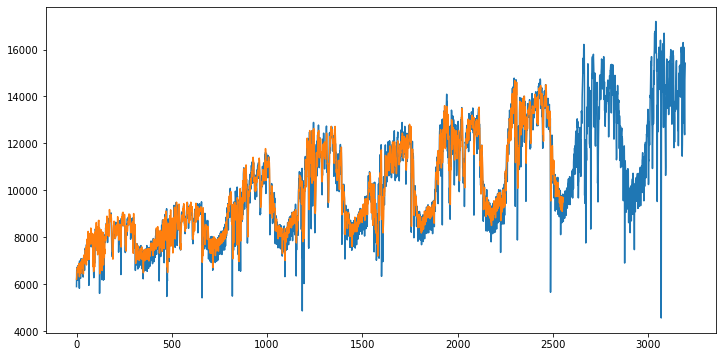

In [102]:
# CNN 

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import Reshape, Flatten, Conv1D, MaxPooling1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = Conv1D(filters=15, kernel_size=7, activation='relu')(inputs)
x =  MaxPooling1D(2)(x)
x = Conv1D(filters=30, kernel_size=5, activation='relu')(x)
x =  MaxPooling1D(2)(x)
x = Conv1D(filters=60, kernel_size=3, activation='relu')(x)
x = Flatten()(x)
x = Dense(20, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)



# Get the models predicted demand in MW values

predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test_long.shape)

forecast_CNN=predictions


plt.figure(figsize=(12,6))
plt.plot(df2[0:],label="data")

plt.plot(predict, label="fitted values")
plt.plot(df2[-len(y_test):-30].index, predictions ,label="forecast values", color='violet')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()



plt.figure(figsize=[12,6])
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], y_test[:-30], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], predictions,label='Forecasted value', color="violet")
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()


In [108]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from sktime.performance_metrics.forecasting import mean_absolute_scaled_error

mase=mean_absolute_scaled_error(y_test, predictions, y_train=y_train)

# Calculate test metrics
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)

r2 = r2_score(y_test, predictions)
evs = explained_variance_score(y_test, predictions)

mape = np.mean(np.abs((y_test[:,0] - predictions) / y_test)) * 100
mpe = np.mean((y_test[:,0] - predictions) / y_test) * 100
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")
print(f"Mean Absolute Scaled Error (MASE): {mase}")





import dill                            #pip install dill --user
import keras
import pickle

# Calling `save('my_model.keras')` creates a zip archive `my_model.keras`.
model.save("CNN_1164.64.keras")

filename = 'CNN_1164.64.pkl'
#dill.dump_session(filename)


## Saving as pickle file

# save the iris classification model as a pickle file
model_pkl_file = "CNN_1164.64.pkl"  

with open(model_pkl_file, 'wb') as file:  
    pickle.dump(model, file)

# It can be used to reconstruct the model identically.
reconstructed_model = keras.models.load_model("CNN_1164.64.keras")
#model = keras.models.load_model('LSTM_model.keras')

# Let's check:
#np.testing.assert_allclose(
#    model.predict(test_input), reconstructed_model.predict(test_input)
#)

# evaluate model 
y_predict = reconstructed_model.predict(x_test)

# check results

y_predict =np.reshape(y_predict,(y_predict.shape[0], y_predict.shape[1]))
#print(x_test.shape)

# un-scaling 
y_predict = scaler.inverse_transform(y_predict*np.ones([1,3]))
y_predict = y_predict[:,0]

rmse= np.sqrt( np.mean((y_predict - y_test[:,0])**2))
print('Root Mean Square Error',rmse)

Mean Squared Error (MSE): 1356389.0238794824
Root-Mean Squared Error (RMSE): 1164.6411566999864
Mean Absolute Error (MAE): 770.4662803208138
R2 Score: 0.702349142835669
Explained Variance Score: 0.7129190501344314
Mean Absolute Percentage Error (MAPE): 6.216109536358683
Mean Percentage Error (MPE): -1.7706763067926272
Mean Absolute Scaled Error (MASE): 20205.577360803636
20/20 [==============================] - 0s 803us/step
Root Mean Square Error 1164.641115721249


Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 30, 1)]           0         
                                                                 
 dense_16 (Dense)            (None, 30, 30)            60        
                                                                 
 dense_17 (Dense)            (None, 30, 60)            1860      
                                                                 
 flatten_1 (Flatten)         (None, 1800)              0         
                                                                 
 dense_18 (Dense)            (None, 20)                36020     
                                                                 
 dense_19 (Dense)            (None, 1)                 21        
                                                                 
Total params: 37961 (148.29 KB)
Trainable params: 37961 (14

ValueError: x and y must have same first dimension, but have shapes (609,) and (639,)

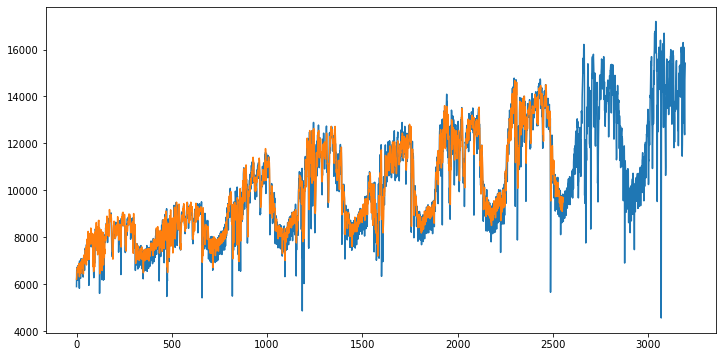

In [109]:
# MLP

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, LayerNormalization, MultiHeadAttention, Dropout, GlobalAveragePooling1D, Reshape
from tensorflow.keras.layers import Reshape, Flatten, Conv1D, MaxPooling1D, TimeDistributed, Concatenate

from sklearn.metrics import mean_squared_error
import math
import matplotlib.pyplot as plt



# Transformer Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = LayerNormalization(epsilon=1e-6)(inputs)
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = Dropout(dropout)(x)
    res = x + inputs

    x = LayerNormalization(epsilon=1e-6)(res)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return x + res

# Model Definition
inputs = Input(shape=(x_train.shape[1], x_train.shape[2]))
x = Dense(30, activation="relu")(inputs)
x = Dense(60, activation="relu")(x)
x=Flatten()(x)
x = Dense(20, activation="relu")(x)
outputs = Dense(1, activation="linear")(x)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="adam", loss="mean_squared_error")

# Model Summary
model.summary()


model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)



20/20 [==============================] - 0s 796us/step
(639, 1)
(639,)
(639, 0, 1)


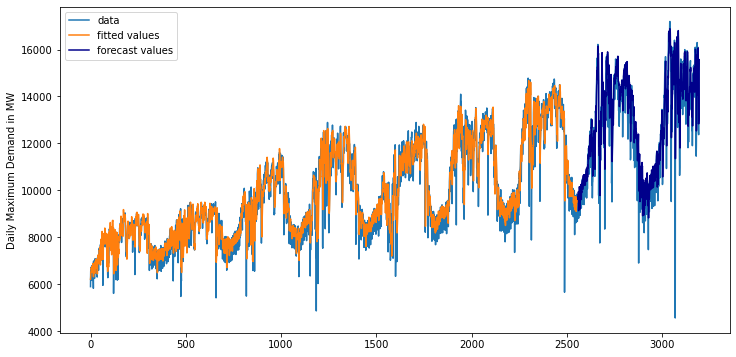

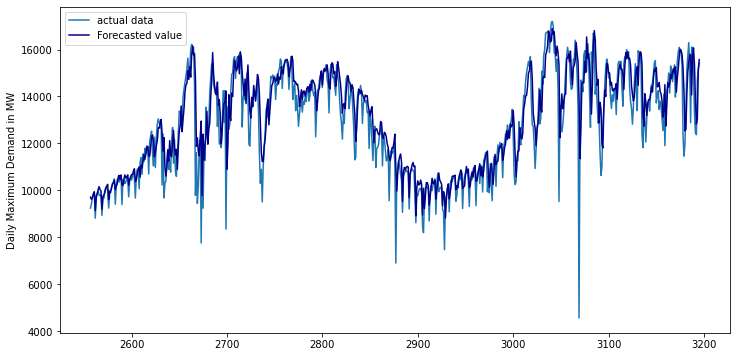

Mean Squared Error (MSE): 1020984.1779975697
Root-Mean Squared Error (RMSE): 1010.4376170736963
Mean Absolute Error (MAE): 634.048154159331
R2 Score: 0.7759515814548509
Explained Variance Score: 0.7900322222633842
Mean Absolute Percentage Error (MAPE): 5.11549029237131
Mean Percentage Error (MPE): -2.0436889504139346
Mean Absolute Scaled Error (MASE): 16627.994445138625
20/20 [==============================] - 0s 803us/step
Root Mean Square Error 1010.4375829294456


In [110]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from sktime.performance_metrics.forecasting import mean_absolute_scaled_error
import dill                            #pip install dill --user
import keras
import pickle


predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test_long.shape)

forecast_MLP=predictions


plt.figure(figsize=(12,6))
plt.plot(df2[0:],label="data")


plt.plot(predict, label="fitted values")
plt.plot(df2[-len(y_test):].index, predictions ,label="forecast values", color='darkblue')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()


plt.figure(figsize=[12,6])
#plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], df2[['Evening Peak Demand']][-len(predictions):], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], y_test, label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], predictions,label='Forecasted value', color="darkblue")
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()




mase=mean_absolute_scaled_error(y_test, predictions, y_train=y_train)

# Calculate test metrics
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)

r2 = r2_score(y_test, predictions)
evs = explained_variance_score(y_test, predictions)

mape = np.mean(np.abs((y_test[:,0] - predictions) / y_test)) * 100
mpe = np.mean((y_test[:,0] - predictions) / y_test) * 100
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")
print(f"Mean Absolute Scaled Error (MASE): {mase}")


# Calling `save('my_model.keras')` creates a zip archive `my_model.keras`.
model.save("CNN_1164.64.keras")

filename = 'CNN_1164.64.pkl'
#dill.dump_session(filename)


## Saving as pickle file

# save the iris classification model as a pickle file
model_pkl_file = "CNN_1164.64.pkl"  

with open(model_pkl_file, 'wb') as file:  
    pickle.dump(model, file)

# It can be used to reconstruct the model identically.
reconstructed_model = keras.models.load_model("CNN_1164.64.keras")
#model = keras.models.load_model('LSTM_model.keras')

# Let's check:
#np.testing.assert_allclose(
#    model.predict(test_input), reconstructed_model.predict(test_input)
#)

# evaluate model 
y_predict = reconstructed_model.predict(x_test)

# check results

y_predict =np.reshape(y_predict,(y_predict.shape[0], y_predict.shape[1]))
#print(x_test.shape)

# un-scaling 
y_predict = scaler.inverse_transform(y_predict*np.ones([1,3]))
y_predict = y_predict[:,0]

rmse= np.sqrt( np.mean((y_predict - y_test[:,0])**2))
print('Root Mean Square Error',rmse)

In [59]:
# LSTM

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Add, Dropout, BatchNormalization
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score

# Define input shape
input_shape = (30, 1)  # Example: 30 time steps, 1 feature

# Input layer
inputs = Input(shape=input_shape)

# First LSTM layer
x = LSTM(units=30, return_sequences=True, activation='tanh')(inputs)


# Second LSTM layer
x = LSTM(units=30, return_sequences=True, activation='tanh')(x)

# Third LSTM layer
x = LSTM(units=30, return_sequences=False, activation='tanh')(x)
# Fully connected layers
x = Dense(units=20, activation="relu")(x)
x = Dropout(0.2)(x)
output = Dense(units=1, activation="linear")(x)  # Forecast output


model = Model(inputs, output)
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Summary 
model.summary()

model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)




predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test_long.shape)

forecast_LSTM=predictions


plt.figure(figsize=(12,6))
plt.plot(df2[0:],label="data")

plt.plot(predict, label="fitted values")
plt.plot(df2[-len(y_test):-30].index, predictions ,label="forecast values", color='deeppink')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()


plt.figure(figsize=[12,6])
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], y_test[:-30], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], predictions,label='Forecasted value', color="deeppink")
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()





# Calculate test metrics
mse = mean_squared_error(y_test[:-30], predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test[:-30], predictions)

r2 = r2_score(y_test[:-30], predictions)
evs = explained_variance_score(y_test[:-30], predictions)

mape = np.mean(np.abs((y_test[:-30][:,0] - predictions) / y_test)) * 100
mpe = np.mean((y_test[:-30][:,0] - predictions) / y_test) * 100
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")


Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 30, 1)]           0         
                                                                 
 lstm_4 (LSTM)               (None, 30, 30)            3840      
                                                                 
 lstm_5 (LSTM)               (None, 30, 30)            7320      
                                                                 
 lstm_6 (LSTM)               (None, 30)                7320      
                                                                 
 dense_8 (Dense)             (None, 20)                620       
                                                                 
 dropout_8 (Dropout)         (None, 20)                0         
                                                                 
 dense_9 (Dense)             (None, 1)                 21  

KeyboardInterrupt: 

In [ ]:
#Residual LSTM

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Add, Dropout, BatchNormalization


input_shape = (30, 1) 


inputs = Input(shape=input_shape)
x = LSTM(units=64, return_sequences=True, activation='tanh')(inputs)
residual_1 = Add()([x, inputs])  # Residual Connection
x = LSTM(units=64, return_sequences=True, activation='tanh')(residual_1)
residual_2 = Add()([x, residual_1])  # Residual Connection
x = LSTM(units=64, return_sequences=False, activation='tanh')(residual_2)
residual_3 = Add()([x, residual_2[:, -1, :]])  # Residual Connection (last time step)
x = BatchNormalization()(residual_3)
x = Dense(units=32, activation="relu")(x)
x = Dropout(0.2)(x)
output = Dense(units=1, activation="linear")(x)  # Forecast output


model = Model(inputs, output)
model.compile(optimizer="adam", loss="mse", metrics=["mae"])


model.summary()


In [105]:
# CNN-ResLSTM-Transformer

import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Add, Dropout, LayerNormalization, MultiHeadAttention, Flatten
from tensorflow.keras.models import Model


input_shape = (30, 1)  # Example: 60 time steps, 1 feature
inputs = Input(shape=input_shape)


x = Conv1D(filters=32, kernel_size=3, activation="relu", padding="same")(inputs)
x = Conv1D(filters=64, kernel_size=5, activation="relu", padding="same")(x)


lstm_out = LSTM(units=64, return_sequences=False)(x)
residual_lstm = Add()([lstm_out, x])  # Residual connection



norm = LayerNormalization(epsilon=1e-6)(residual_lstm)
attention_output = MultiHeadAttention(num_heads=4, key_dim=64)(norm, norm)
attention_residual = Add()([attention_output, residual_lstm])  # Residual connection

x = Dense(units=64, activation="relu")(attention_residual)
x = Dropout(0.2)(x)
x=  Flatten()(x)
output = Dense(units=1, activation="linear")(x)  # Forecast output


model = Model(inputs, output)
model.compile(optimizer="adam", loss="mse", metrics=["mae"])


model.summary()

model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Model: "model_5"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_8 (InputLayer)           [(None, 30, 1)]      0           []                               
                                                                                                  
 conv1d_12 (Conv1D)             (None, 30, 32)       128         ['input_8[0][0]']                
                                                                                                  
 conv1d_13 (Conv1D)             (None, 30, 64)       10304       ['conv1d_12[0][0]']              
                                                                                                  
 lstm_8 (LSTM)                  (None, 64)           33024       ['conv1d_13[0][0]']              
                                                                                            

KeyboardInterrupt: 

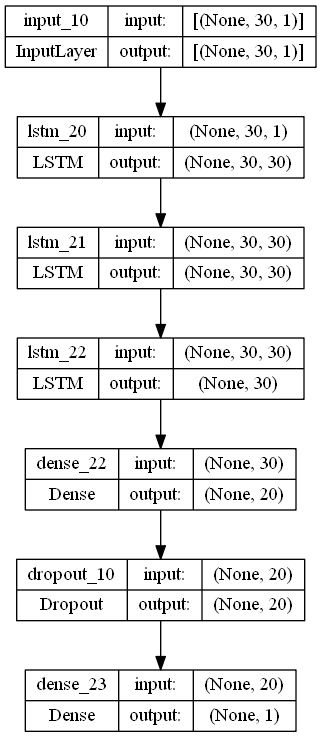

In [166]:
import keras

keras.utils.plot_model(model, "ensemble_model.png", show_shapes=True)

In [87]:
model.summary()


Model: "model_5"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_6 (InputLayer)        [(None, 30, 1)]              0         []                            
                                                                                                  
 lstm_4 (LSTM)               (None, 30, 30)               3840      ['input_6[0][0]']             
                                                                                                  
 lstm_5 (LSTM)               (None, 30)                   7320      ['lstm_4[0][0]']              
                                                                                                  
 reshape_2 (Reshape)         (None, 30, 1)                0         ['lstm_5[0][0]']              
                                                                                            

79/79 [==============================] - 2s 7ms/step
(2497, 1)
(2497,)
Root Mean Square Error 663.9547816647733
Mean Squared Error (MSE): 440835.9520955168
Root-Mean Squared Error (RMSE): 663.9547816647733
Mean Absolute Error (MAE): 475.1942025486661
R2 Score: 0.8817166984965045
Explained Variance Score: 0.8847080142572218
Mean Absolute Percentage Error (MAPE): 5.015388547267731
Mean Percentage Error (MPE): 0.4828291825492794


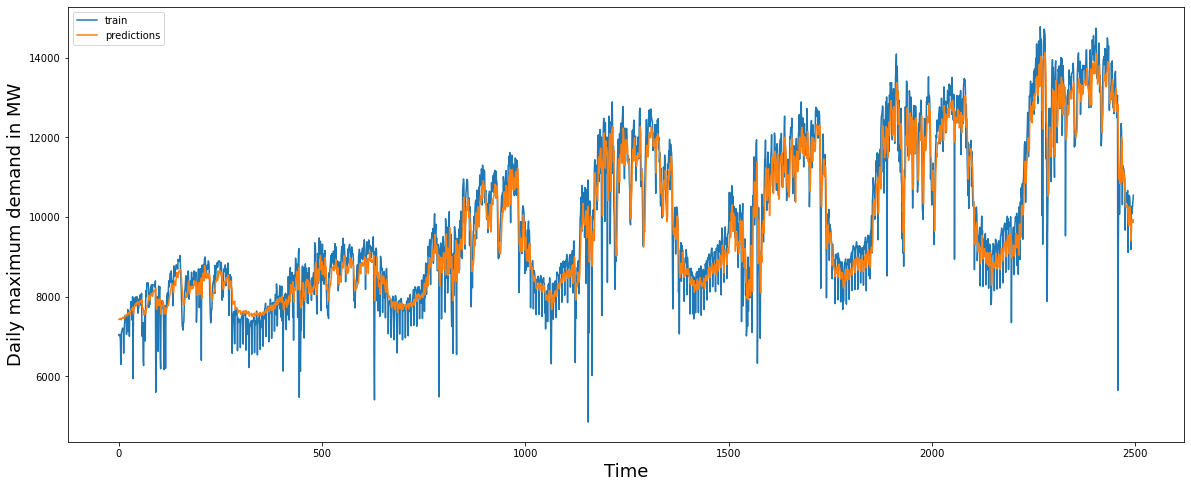

In [227]:
## Training Error

# Get the models predicted price values

predictions = model.predict(x_train)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions*np.ones([1,3]))
predictions = predictions[:,0]
print(predictions.shape)
#print(y_test.shape)

y_train_unscaled = scaler.inverse_transform(y_train*np.ones([1,3]))
y_train_unscaled = y_train_unscaled[:,0]



y_test=y_test#[:,0]
rmse= np.sqrt( np.mean((predictions - y_train_unscaled)**2))
print('Root Mean Square Error',rmse)

# Calculate test metrics
mse = mean_squared_error(y_train_unscaled, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_train_unscaled , predictions)

r2 = r2_score(y_train_unscaled, predictions)
evs = explained_variance_score(y_train_unscaled, predictions)

mape = np.mean(np.abs((y_train_unscaled - predictions) / y_train_unscaled)) * 100
mpe = np.mean((y_train_unscaled - predictions) / y_train_unscaled) * 100

print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")


plt.figure(figsize=([20,8]))
plt.plot(y_train_unscaled, label='train')
plt.plot(predictions, label='predictions')
plt.xlabel('Time', fontsize=18)
plt.ylabel('Daily maximum demand in MW', fontsize=18)
plt.legend()
plt.show()

prediction_training= predictions

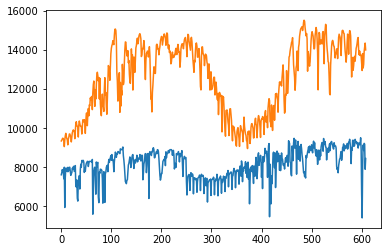

In [162]:
plt.plot(y_test[:,28,0])
plt.plot(predictions)

20/20 [==============================] - 1s 6ms/step
(609, 1)
(609,)
(609, 30, 1)


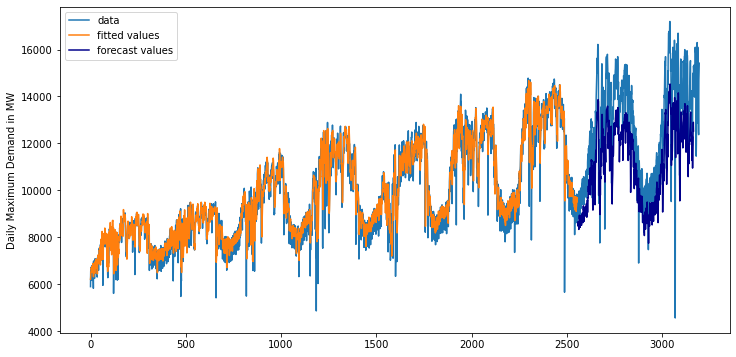

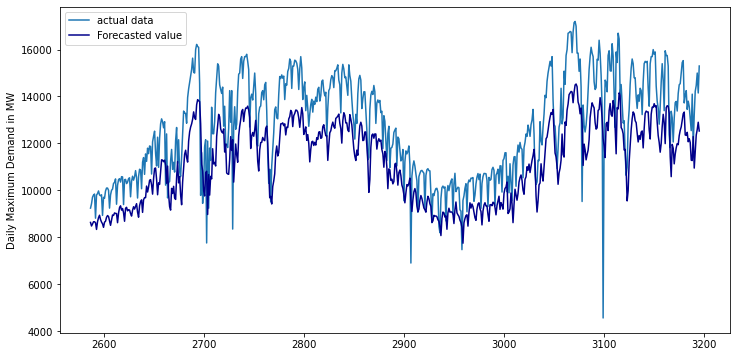

Mean Squared Error (MSE): 3164293.9820208703
Root-Mean Squared Error (RMSE): 1778.8462502478594
Mean Absolute Error (MAE): 1592.3537264919437
R2 Score: 0.2985900597175869
Explained Variance Score: 0.782036395980116
Mean Absolute Percentage Error (MAPE): 12.847084210332469
Mean Percentage Error (MPE): 11.914933242603128


In [256]:


predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))


# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test_long.shape)

forecast_CNN_ResLSTM_ConNet=predictions


plt.figure(figsize=(12,6))
plt.plot(df2[0:],label="data")


plt.plot(predict, label="fitted values")
plt.plot(df2[-len(y_test):-30].index, predictions ,label="forecast values", color='darkblue')
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()



plt.figure(figsize=[12,6])
#plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], df2[['Evening Peak Demand']][-len(predictions):], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], y_test[:-30], label='actual data')
plt.plot(df2[['Evening Peak Demand']].index[-len(predictions):], predictions,label='Forecasted value', color="darkblue")
plt.ylabel("Daily Maximum Demand in MW")
plt.legend()
plt.show()



from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score#, root_mean_squared_log_error

mse = mean_squared_error(y_test[:-30], predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test[:-30], predictions)

r2 = r2_score(y_test[:-30], predictions)
evs = explained_variance_score(y_test[:-30], predictions)

mape = np.mean(np.abs((y_test[:-30][:,0] - predictions) / y_test)) * 100
mpe = np.mean((y_test[:-30][:,0] - predictions) / y_test) * 100
print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")


In [73]:
from sktime.performance_metrics.forecasting import mean_absolute_scaled_error

print(mean_absolute_scaled_error(y_test, forecast_STL_ES.values[1:], y_train=y_train))
print(mean_absolute_scaled_error(y_test, forecast_STL_ARIMA.values[1:], y_train=y_train))
print(mean_absolute_scaled_error(y_test, forecast_Classical_ARIMA.values[1:], y_train=y_train))
print(mean_absolute_scaled_error(y_test, forecast_Classical_ETS[1:], y_train=y_train))
print(mean_absolute_scaled_error(y_test[:-30], forecast_CNN, y_train=y_train))
print(mean_absolute_scaled_error(y_test[:-30], forecast_LSTM, y_train=y_train))
print(mean_absolute_scaled_error(y_test[:-30], forecast_MLP, y_train=y_train))
print(mean_absolute_scaled_error(y_test[:-30], forecast_LSTM_mTrans_MLP, y_train=y_train))
print(mean_absolute_scaled_error(y_test[:-30], forecast_CNN_ResLSTM_ConNet, y_train=y_train))


y_test[]


29112.16123081911
28997.867789832624
42324.73069186128
47416.463103429676


NameError: name 'forecast_CNN' is not defined

In [91]:
def RMSLE(y_test, y_pred):
    rmsle=np.sqrt(np.mean((np.log(y_test+1)-np.log(y_pred+1))**2))
    return rmsle



In [101]:
#RMSLE(y_test[:,0], forecast_STL_ES.values)
print(np.log(y_test[:,0]+1))

AttributeError: 'numpy.ndarray' object has no attribute 'float'

In [267]:
sum=0
MASEnaive=np.mean(np.abs(y_train[365:]-y_train[:-365]))
MAE= np.mean(np.abs(y_test[:-30]-forecast_MLP))

print(MAE/MASEnaive)



26633.80882516619


In [46]:
print(forecast_Classical_ARIMA)

2556    11364.361176
2557    11319.761510
2558    11323.931068
2559    11438.361961
2560    11464.522601
            ...     
3191    11381.140160
3192    11138.742452
3193    11393.348771
3194    11363.198717
3195    11249.364279
Name: predicted_mean, Length: 640, dtype: float64


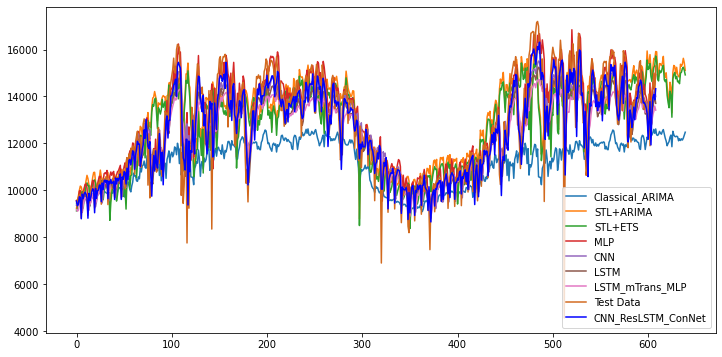

In [206]:
plt.figure(figsize=[12,6])


plt.plot(forecasted_with_seasonality, label="Classical_ARIMA")
#plt.plot(forecast_Classical_STL, label="Classical_STL")
plt.plot(forecast_STL_ARIMA.values, label="STL+ARIMA")
plt.plot(forecast_STL_ES.values, label="STL+ETS")
plt.plot(forecast_MLP, label="MLP")
plt.plot(forecast_CNN, label="CNN")
plt.plot(forecast_LSTM, label="LSTM")
plt.plot(forecast_LSTM_mTrans_MLP, label="LSTM_mTrans_MLP")
plt.plot(y_test[:-30], label='Test Data',color="chocolate")
plt.plot(forecast_CNN_ResLSTM_ConNet, label="CNN_ResLSTM_ConNet", color="blue")

plt.legend(loc="lower right")
plt.show()


In [208]:
print(length)

NameError: name 'length' is not defined

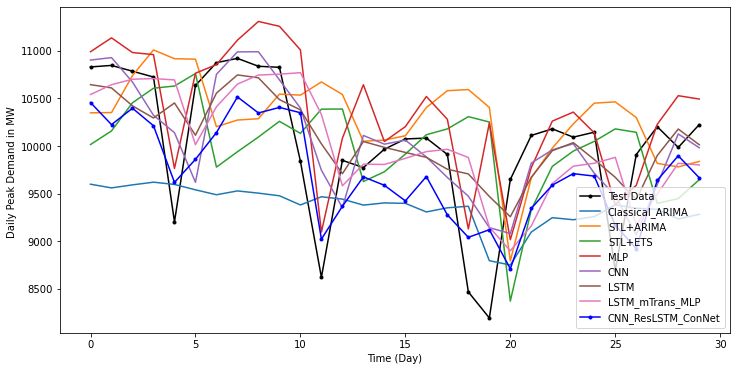

In [244]:

start=330
length=30
end=start+length

plt.figure(figsize=[12,6])
plt.plot(y_test[start:end], label='Test Data',marker='.', color="black")
plt.plot(forecasted_with_seasonality[start:end], label="Classical_ARIMA")

plt.plot(forecast_STL_ARIMA.values[start:end], label="STL+ARIMA")
plt.plot(forecast_STL_ES.values[start:end], label="STL+ETS")
plt.plot(forecast_MLP[start:end], label="MLP")
plt.plot(forecast_CNN[start:end], label="CNN")
plt.plot(forecast_LSTM[start:end], label="LSTM")
plt.plot(forecast_LSTM_mTrans_MLP[start:end], label="LSTM_mTrans_MLP")
plt.plot(forecast_CNN_ResLSTM_ConNet[start:end], label="CNN_ResLSTM_ConNet", marker='.', color="blue")
plt.xlabel("Time (Day)")
plt.ylabel("Daily Peak Demand in MW ")
#plt.plot(forecast_Classical_ETS)
plt.legend(loc="lower right")
plt.show()

In [184]:


predictions = model.predict(x_test)
print(predictions.shape)

predictions=np.reshape(predictions,(predictions.shape[0], predictions.shape[1]))
#print(x_test.shape)

# un-scaling 
predictions = scaler.inverse_transform(predictions)
predictions = predictions[:,0]
print(predictions.shape)
print(y_test_long.shape)

forecast_Res_LSTM=predictions

rmse= np.sqrt(np.mean((predictions - y_test[:,0])**2))
print('Root Mean Square Error',rmse)

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score


# Calculate test metrics
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test , predictions)

r2 = r2_score(y_test, predictions)
evs = explained_variance_score(y_test, predictions)

mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100
mpe = np.mean((y_test - predictions) / y_test) * 100

print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")


20/20 [==============================] - 0s 7ms/step
(609, 1)
(609,)
(609, 30, 1)
Root Mean Square Error 933.7599369105036


ValueError: Found input variables with inconsistent numbers of samples: [639, 609]

In [149]:

rmse= np.sqrt( np.mean((predictions - y_test)**2))
print('Root Mean Square Error',rmse)

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score


# Calculate test metrics
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test , predictions)

r2 = r2_score(y_test, predictions)
evs = explained_variance_score(y_test, predictions)

mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100
mpe = np.mean((y_test - predictions) / y_test) * 100

print(f"Mean Squared Error (MSE): {mse}")
print(f"Root-Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")


Root Mean Square Error 4828.070933184832


ValueError: Found array with dim 3. Estimator expected <= 2.

In [52]:
model.fit(x_train, y_train,  epochs=25, batch_size=1, verbose=1)

Epoch 1/25
2527/2527 [==============================] - 2s 826us/step - loss: 0.0031
Epoch 2/25
2527/2527 [==============================] - 2s 768us/step - loss: 0.0034
Epoch 3/25
2527/2527 [==============================] - 2s 714us/step - loss: 0.0033
Epoch 4/25
2527/2527 [==============================] - 2s 707us/step - loss: 0.0032
Epoch 5/25
2527/2527 [==============================] - 2s 673us/step - loss: 0.0033
Epoch 6/25
2527/2527 [==============================] - 2s 721us/step - loss: 0.0031
Epoch 7/25
2527/2527 [==============================] - 2s 683us/step - loss: 0.0031
Epoch 8/25
2527/2527 [==============================] - 2s 679us/step - loss: 0.0031
Epoch 9/25
2527/2527 [==============================] - 2s 677us/step - loss: 0.0031
Epoch 10/25
2527/2527 [==============================] - 2s 702us/step - loss: 0.0030
Epoch 11/25
2527/2527 [==============================] - 2s 716us/step - loss: 0.0030
Epoch 12/25
2527/2527 [==============================] - 2s 702

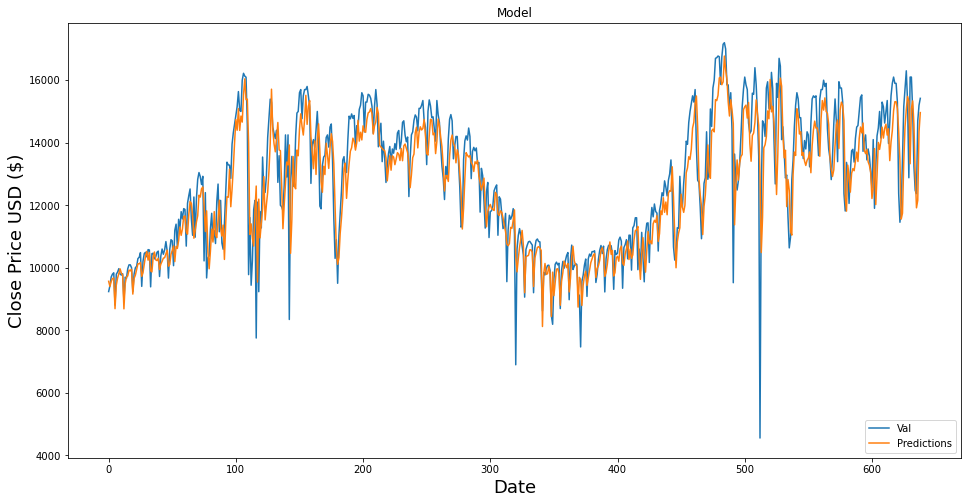

1010.3653855443214


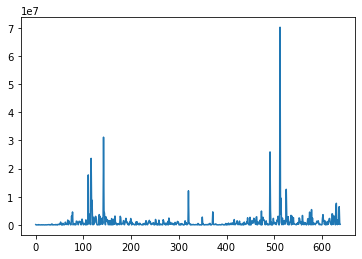

In [64]:
#plot the data

train=dataset[:training_data_len]
valid = dataset[training_data_len:]
valid2=predictions

plt.figure(figsize=(16,8))
plt.title('Model')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)

plt.plot(valid, label='test Data')
plt.plot(valid2, label='Predictions')

plt.legend(['Val', 'Predictions'], loc = 'lower right')

plt.show()


error=((y_test[:,0]-predictions)**2)
plt.plot(error)

print(np.sqrt(np.sum(error)/len(error)))

# Saving Model

In [185]:
import dill                            #pip install dill --user
import keras
import pickle


model.save("CNN_ResLSTM_ConNet_933.75.keras")

filename = 'CNN_ResLSTM_ConNet_933.75.pkl'



## Saving as pickle file


model_pkl_file = "CNN_ResLSTM_ConNet_933.75.pkl"  

with open(model_pkl_file, 'wb') as file:  
    pickle.dump(model, file)



# Load Model from disk

In [252]:
# load model from keras file


import numpy as np
import keras
import dill                            #pip install dill --user
import pickle
from sklearn.metrics import classification_report


## From Keras file:



reconstructed_model = keras.models.load_model("CNN_ResLSTM_ConNet_933.75.keras")

# Let's check:
np.testing.assert_allclose(
    reconstructed_model.predict(x_test), reconstructed_model.predict(x_test)
)


# From pickle file: 

model_pkl_file = "CNN_ResLSTM_ConNet_933.75.pkl" 

with open(model_pkl_file, 'rb') as file:  
    reconstructed_model = pickle.load(file)


        
# evaluate model 
y_predict = reconstructed_model.predict(x_test)

# check results

y_predict =np.reshape(y_predict,(y_predict.shape[0], y_predict.shape[1]))
#print(x_test.shape)

# un-scaling 
y_predict = scaler.inverse_transform(y_predict*np.ones([1,3]))
y_predict = y_predict[:,0]

rmse= np.sqrt( np.mean((y_predict - y_test[:-30,0])**2))
print('Root Mean Square Error',rmse)

20/20 [==============================] - 1s 7ms/step
Root Mean Square Error 933.7599548996048


In [253]:
forecast_CNN_ResLSTM_ConNet= y_predict

In [115]:
y_predict = reconstructed_model.predict(x_test)
y_predict_NEW=y_predict
x_test_new=x_test[0:1,:,:]
y_predict_new=np.zeros([30,1])
for i in range(x_test.shape[0]):
    y_predict = reconstructed_model.predict(x_test_new)
    y_predict_new=y_predict
    y_predict_NEW[i,:]=y_predict
    x_test_new[0,0:29,:]=x_test_new[0,1:30,:]
    x_test_new[0,29,:]=y_predict_new


1/1 [==============================] - 0s 21ms/step


1/1 [==============================] - 0s 17ms/step


1/1 [==============================] - 0s 16ms/step


In [119]:
#print(y_predict_NEW)

# check results

y_predict_NEW =np.reshape(y_predict_NEW,(y_predict_NEW.shape[0], y_predict_NEW.shape[1]))
#print(x_test.shape)

# un-scaling 
y_predict_NEW = scaler.inverse_transform(y_predict_NEW*np.ones([1,3]))
y_predict_NEW = y_predict_NEW[:,0]



IndexError: tuple index out of range

# Prophet Model

In [2]:
from fbprophet import Prophet
m = Prophet(daily_seasonality = True) # the Prophet class (model)
m.fit(train_x) # fit the model using all data

ModuleNotFoundError: No module named 'fbprophet'

In [3]:
future = m.make_future_dataframe(periods=365) #we need to specify the number of days in future
prediction = m.predict(future)
m.plot(prediction)
plt.title("Prediction of the Tesla Stock Price using the Prophet")
plt.xlabel("Date")
plt.ylabel("Close Stock Price")
plt.show()

NameError: name 'm' is not defined

In [4]:
m.plot_components(prediction)
plt.show()

NameError: name 'm' is not defined

In [1]:
from prophet import Prophet
import warnings
warnings.filterwarnings("ignore")


C:\Users\dipayan\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\dipayan\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [38]:
appl = data1[['Date', 'value']]
appl.columns = ['ds', 'y'] 
appl.head(3)


,ds,y
0,2016-01-01,5891.0
1,2016-01-02,6538.0
2,2016-01-03,6635.0


In [53]:
print(testData.info())
print(test_data.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 639 entries, 2023-01-01 to 2024-09-30
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Evening Peak Demand  639 non-null    Float64
dtypes: Float64(1)
memory usage: 10.6 KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 2556 to 3195
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Evening Peak Demand  640 non-null    Float64
dtypes: Float64(1)
memory usage: 5.8 KB
None


In [67]:
model = Prophet()
model.fit(appl[:2557]) 
future = model.make_future_dataframe(periods=639, freq="D")
forecast_Prophet = model.predict(future)



print("################  Result on test data ###################")
forecast=forecast_Prophet.yhat[2557:]

# Calculate training metrics
#forecast=np.array(forecasted_with_seasonality)
#forecast=forecast.reshape([forecast.shape[0],1])
plt.figure(figsize=([12,6]))
plt.plot(df2['Evening Peak Demand'], label='data')
plt.plot(df2['Evening Peak Demand'].index[:int(len(df2)*0.8)],train_data, label='fitted data')
plt.plot(df2['Evening Peak Demand'].index[int(len(df2)*0.8+1):],forecast, label='Forecasted value')
plt.legend()
plt.show()

#forecast=forecast_STL_ES

# Calculate training metrics
#forecast=np.array(forecasted_with_seasonality)
#forecast=forecast.reshape([forecast.shape[0],1])
mse = mean_squared_error(testData, forecast)
rmse = np.sqrt(mse)
mae = mean_absolute_error(testData, forecast)
r2 = r2_score(testData, forecast)
evs = explained_variance_score(testData, forecast)
mape = np.mean(np.abs((testData['Evening Peak Demand'].values - forecast.values) / testData['Evening Peak Demand'].values)) * 100
mpe = np.mean((testData['Evening Peak Demand'].values - forecast.values) / testData['Evening Peak Demand'].values) * 100


print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")
print(f"Explained Variance Score: {evs}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}")
print(f"Mean Percentage Error (MPE): {mpe}")



NameError: name 'Prophet' is not defined

In [81]:
print(dir(model))
print("\n\n\n")
print(model.__dir__())
print("\n\n\n")
print(model.predict())

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_load_stan_backend', '_logistic_uncertainty', '_make_historical_mat_time', '_make_trend_shift_matrix', '_sample_uncertainty', 'add_country_holidays', 'add_group_component', 'add_regressor', 'add_seasonality', 'calculate_initial_params', 'changepoint_prior_scale', 'changepoint_range', 'changepoints', 'changepoints_t', 'component_modes', 'construct_holiday_dataframe', 'country_holidays', 'daily_seasonality', 'extra_regressors', 'fit', 'fit_kwargs', 'flat_growth_init', 'flat_trend', 'fourier_series', 'growth', 'history', 'history_dates', 'holidays', 'holidays_mode', 'holidays_prior_scale', 'initialize_scales', 'interval_width', 'linear_growth_init',

In [68]:

model.plot(forecast)
plt.xlabel('Time')
plt.ylabel('Daily maximum demand, MW')
plt.title("Forecasting with Prophet Model")
plt.show()

AttributeError: 'Functional' object has no attribute 'plot'